In [ ]:
import pandas as pd
import statistics as st
import matplotlib.pyplot as plt
import optuna
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size" : 20})

: 

In [ ]:
def obter_df(local):
    # Este pedi para o claude, dado que não sabia buscar um study
    s = optuna.study.get_all_study_summaries(storage=f"sqlite:///./studies/{local}.db")

    estudo = optuna.load_study(study_name=f"{s[0].study_name}", storage=f"sqlite:///./studies/{local}.db")
    df = estudo.trials_dataframe()
    df = df.dropna(axis=1)
    df = df.drop(['number', 'datetime_start','datetime_complete', 'duration', 'state'], axis=1)

    return(df)

def melhores_scores(df):
    quartis = st.quantiles(df['value'])
    return df.loc[df['value'] > quartis[2]]

def plotar(df, arquivo='',salvar=False):
    colunas = list(df.columns)
    n_cols = len(colunas)
    max_linhas = (n_cols + 3 - 1) // 3

    figura, eixos = plt.subplots(max_linhas, 3, figsize=(n_cols*5, max_linhas*10))

    eixos = eixos.flatten()

    for i in range(len(colunas)):
            dados_coluna = df[colunas[i]]
            
            # Uso de I.A
            is_bool = pd.api.types.is_bool_dtype(dados_coluna)
            is_numeric = pd.api.types.is_numeric_dtype(dados_coluna) and not is_bool

            if is_numeric:
                # Se for estritamente numérica, gera o histograma convencional
                eixos[i].hist(dados_coluna, edgecolor='black', alpha=0.7)
            else:
                # Se for booleana ou texto, calcula a contagem e plota como gráfico de barras
                contagem = dados_coluna.astype(str).value_counts()
                eixos[i].bar(contagem.index, contagem.values, edgecolor='black', alpha=0.7, color='skyblue')
                
            eixos[i].set(xlabel=f"{colunas[i]}", ylabel="Contagem")
            eixos[i].set_title(f"Distribuição de {colunas[i]}")

    for i in range(n_cols, len(eixos)):
        figura.delaxes(eixos[i])

    if salvar:
        plt.savefig(f'./figuras/{arquivo}')
    
    plt.tight_layout()
    plt.show()

def ciclo(local):
    df = obter_df(local)
    melhores = melhores_scores(df)
    plotar(melhores, salvar=True, arquivo=f'{local}.png')

    

## Primeiro ciclo

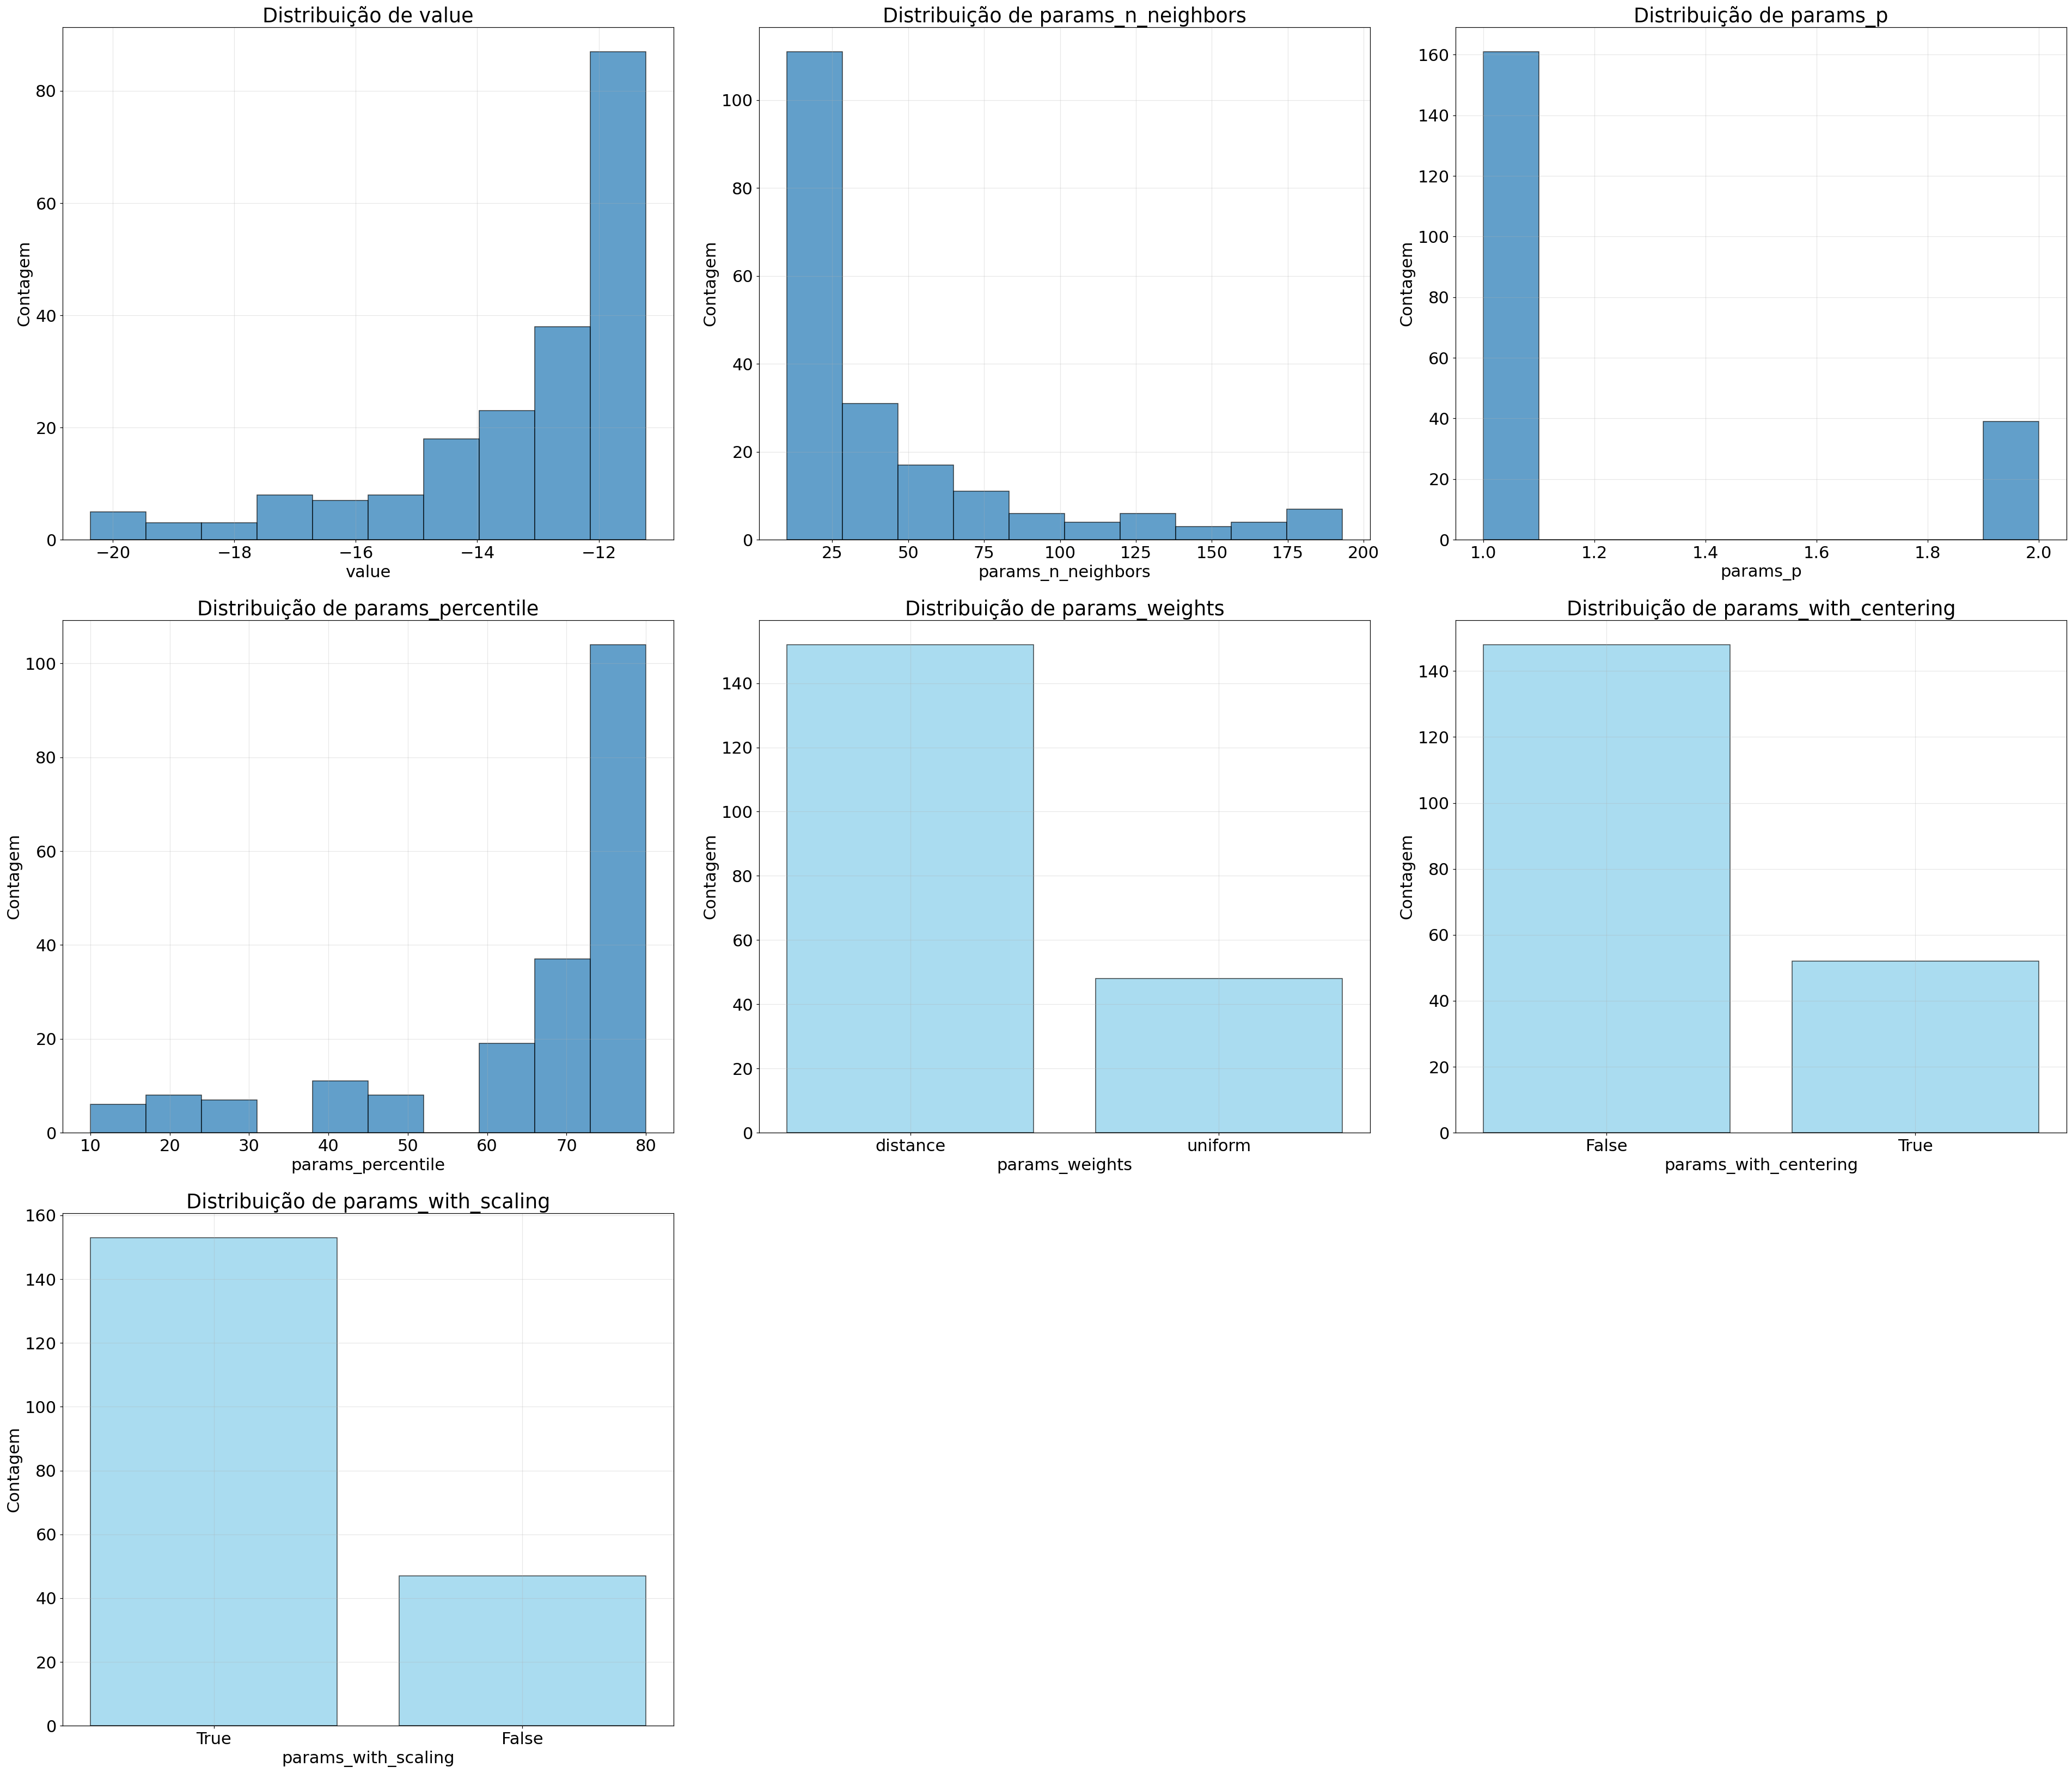

In [71]:
df_knn = obter_df('KNN_inicial')
plotar(df_knn)

Comparando com apenas os 25% melhores trials:

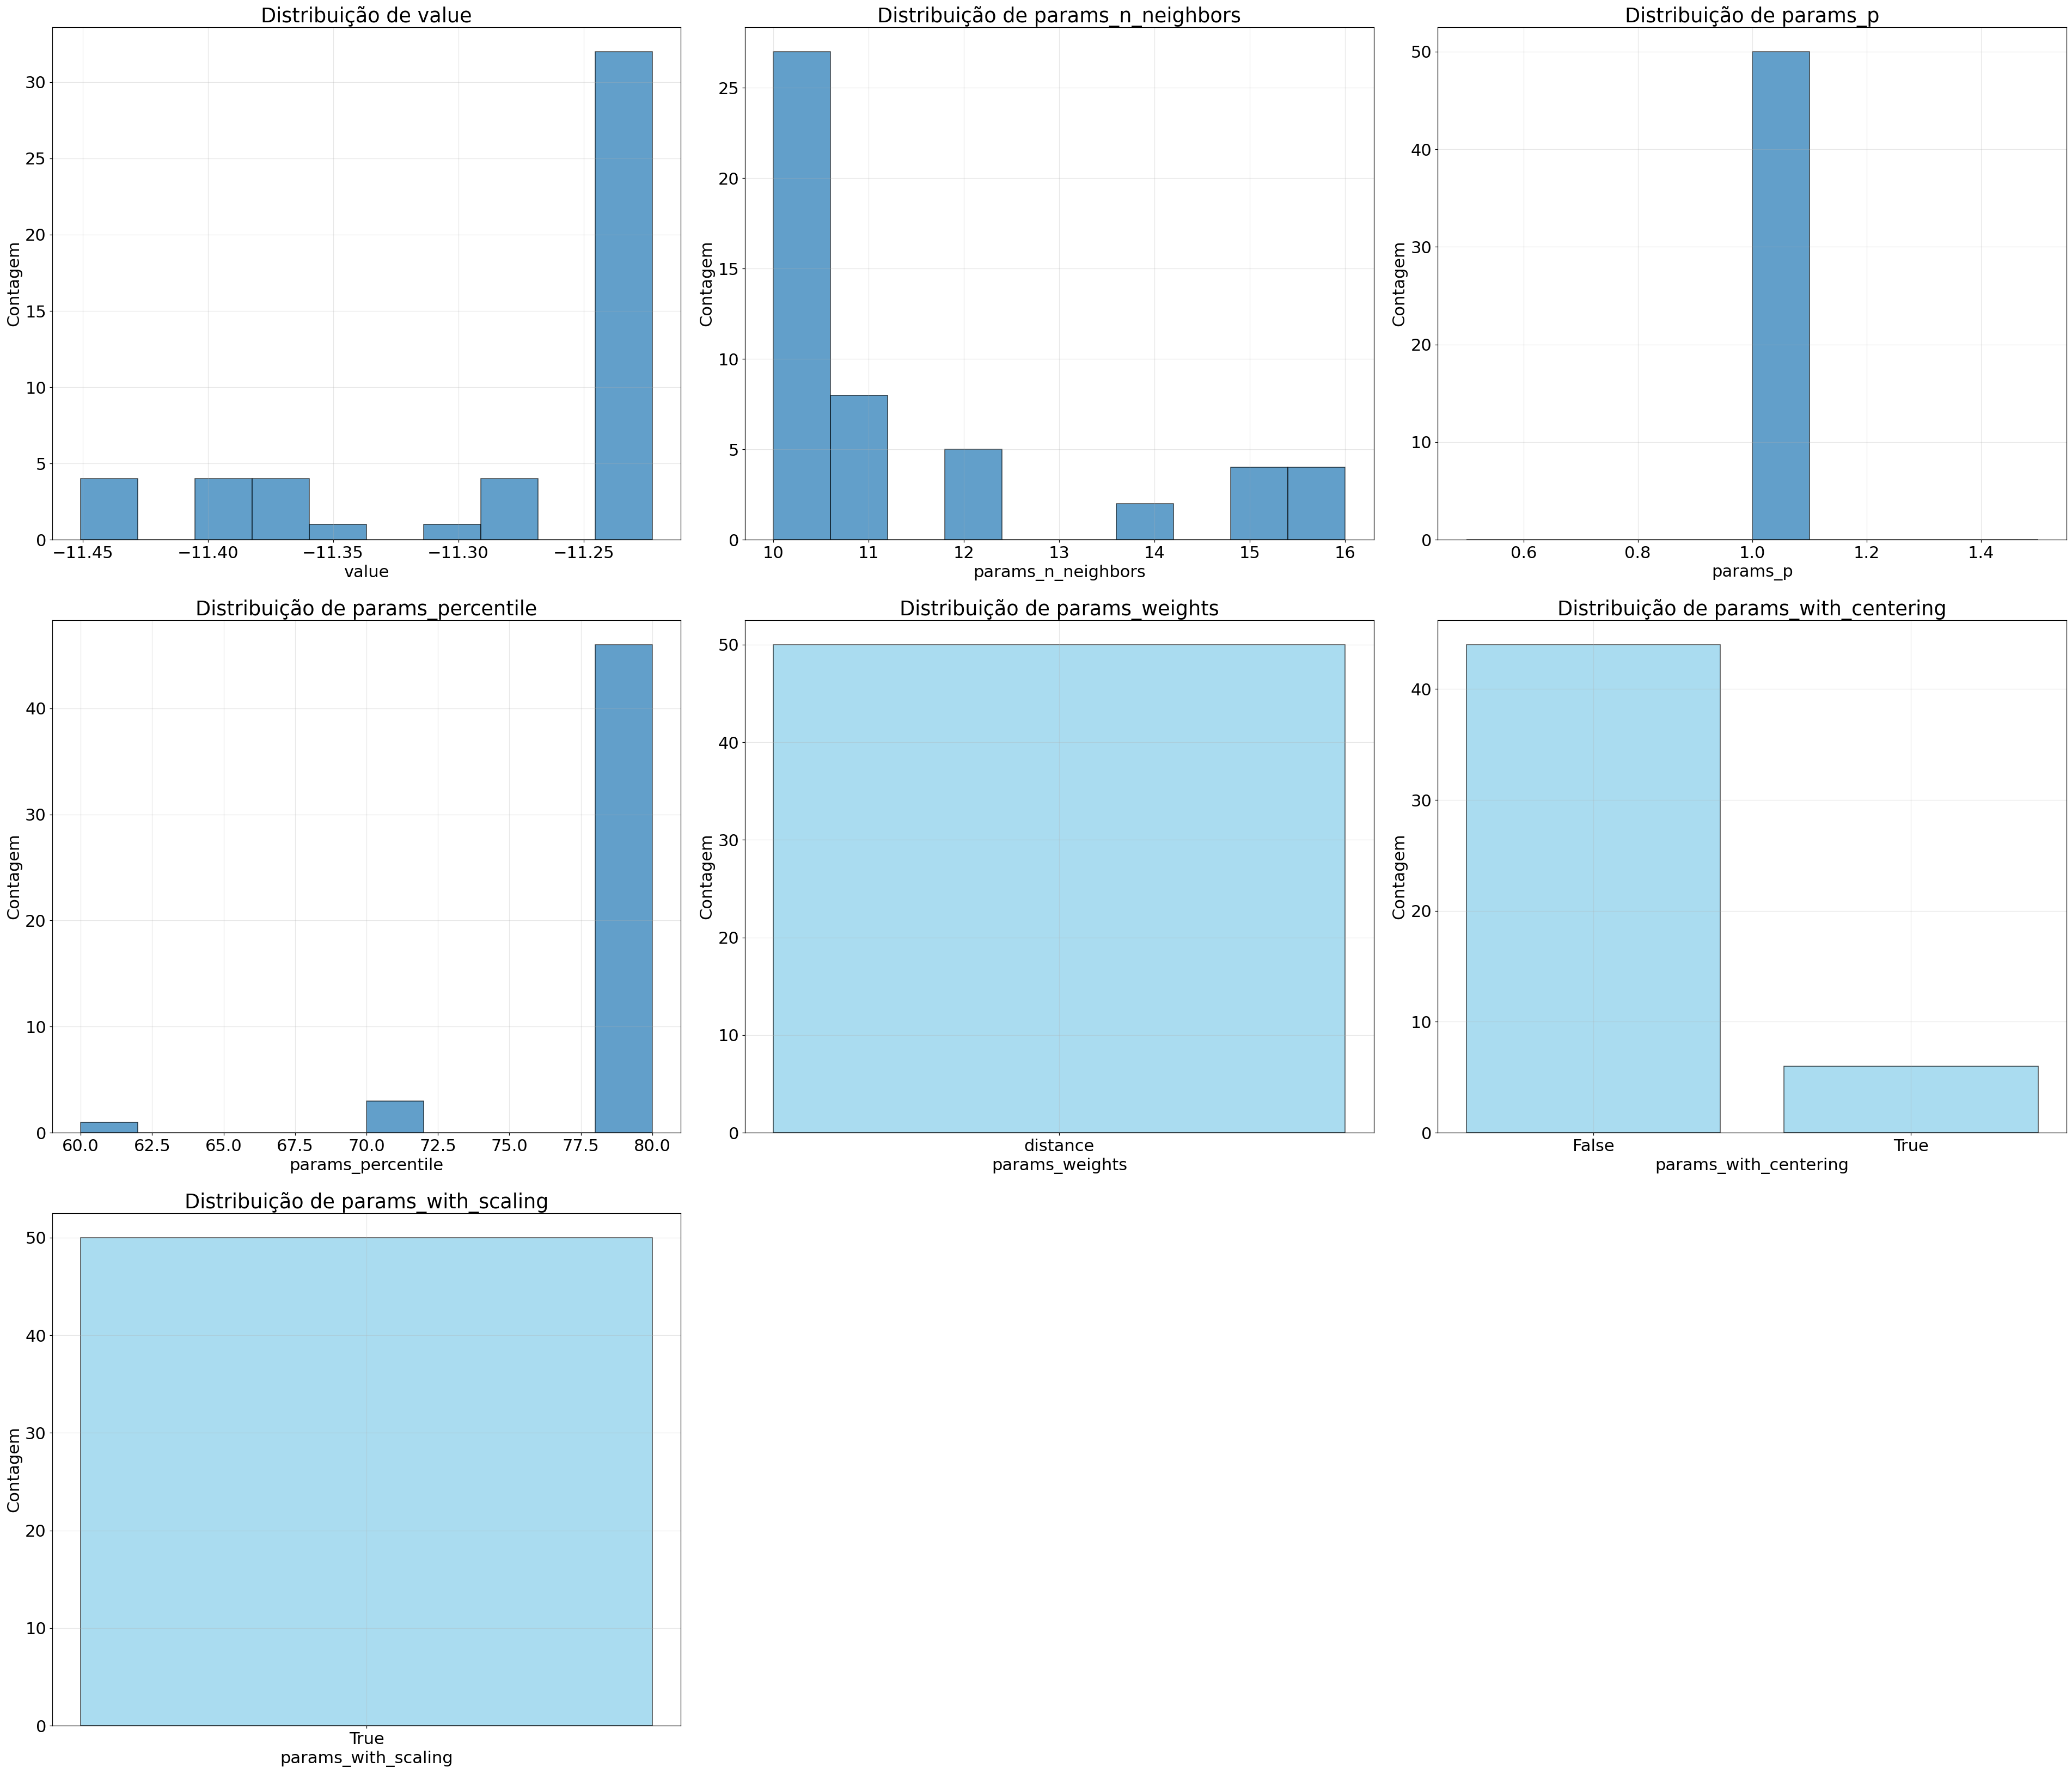

In [72]:
melhores_knns = melhores_scores(df_knn)
plotar(melhores_knns)

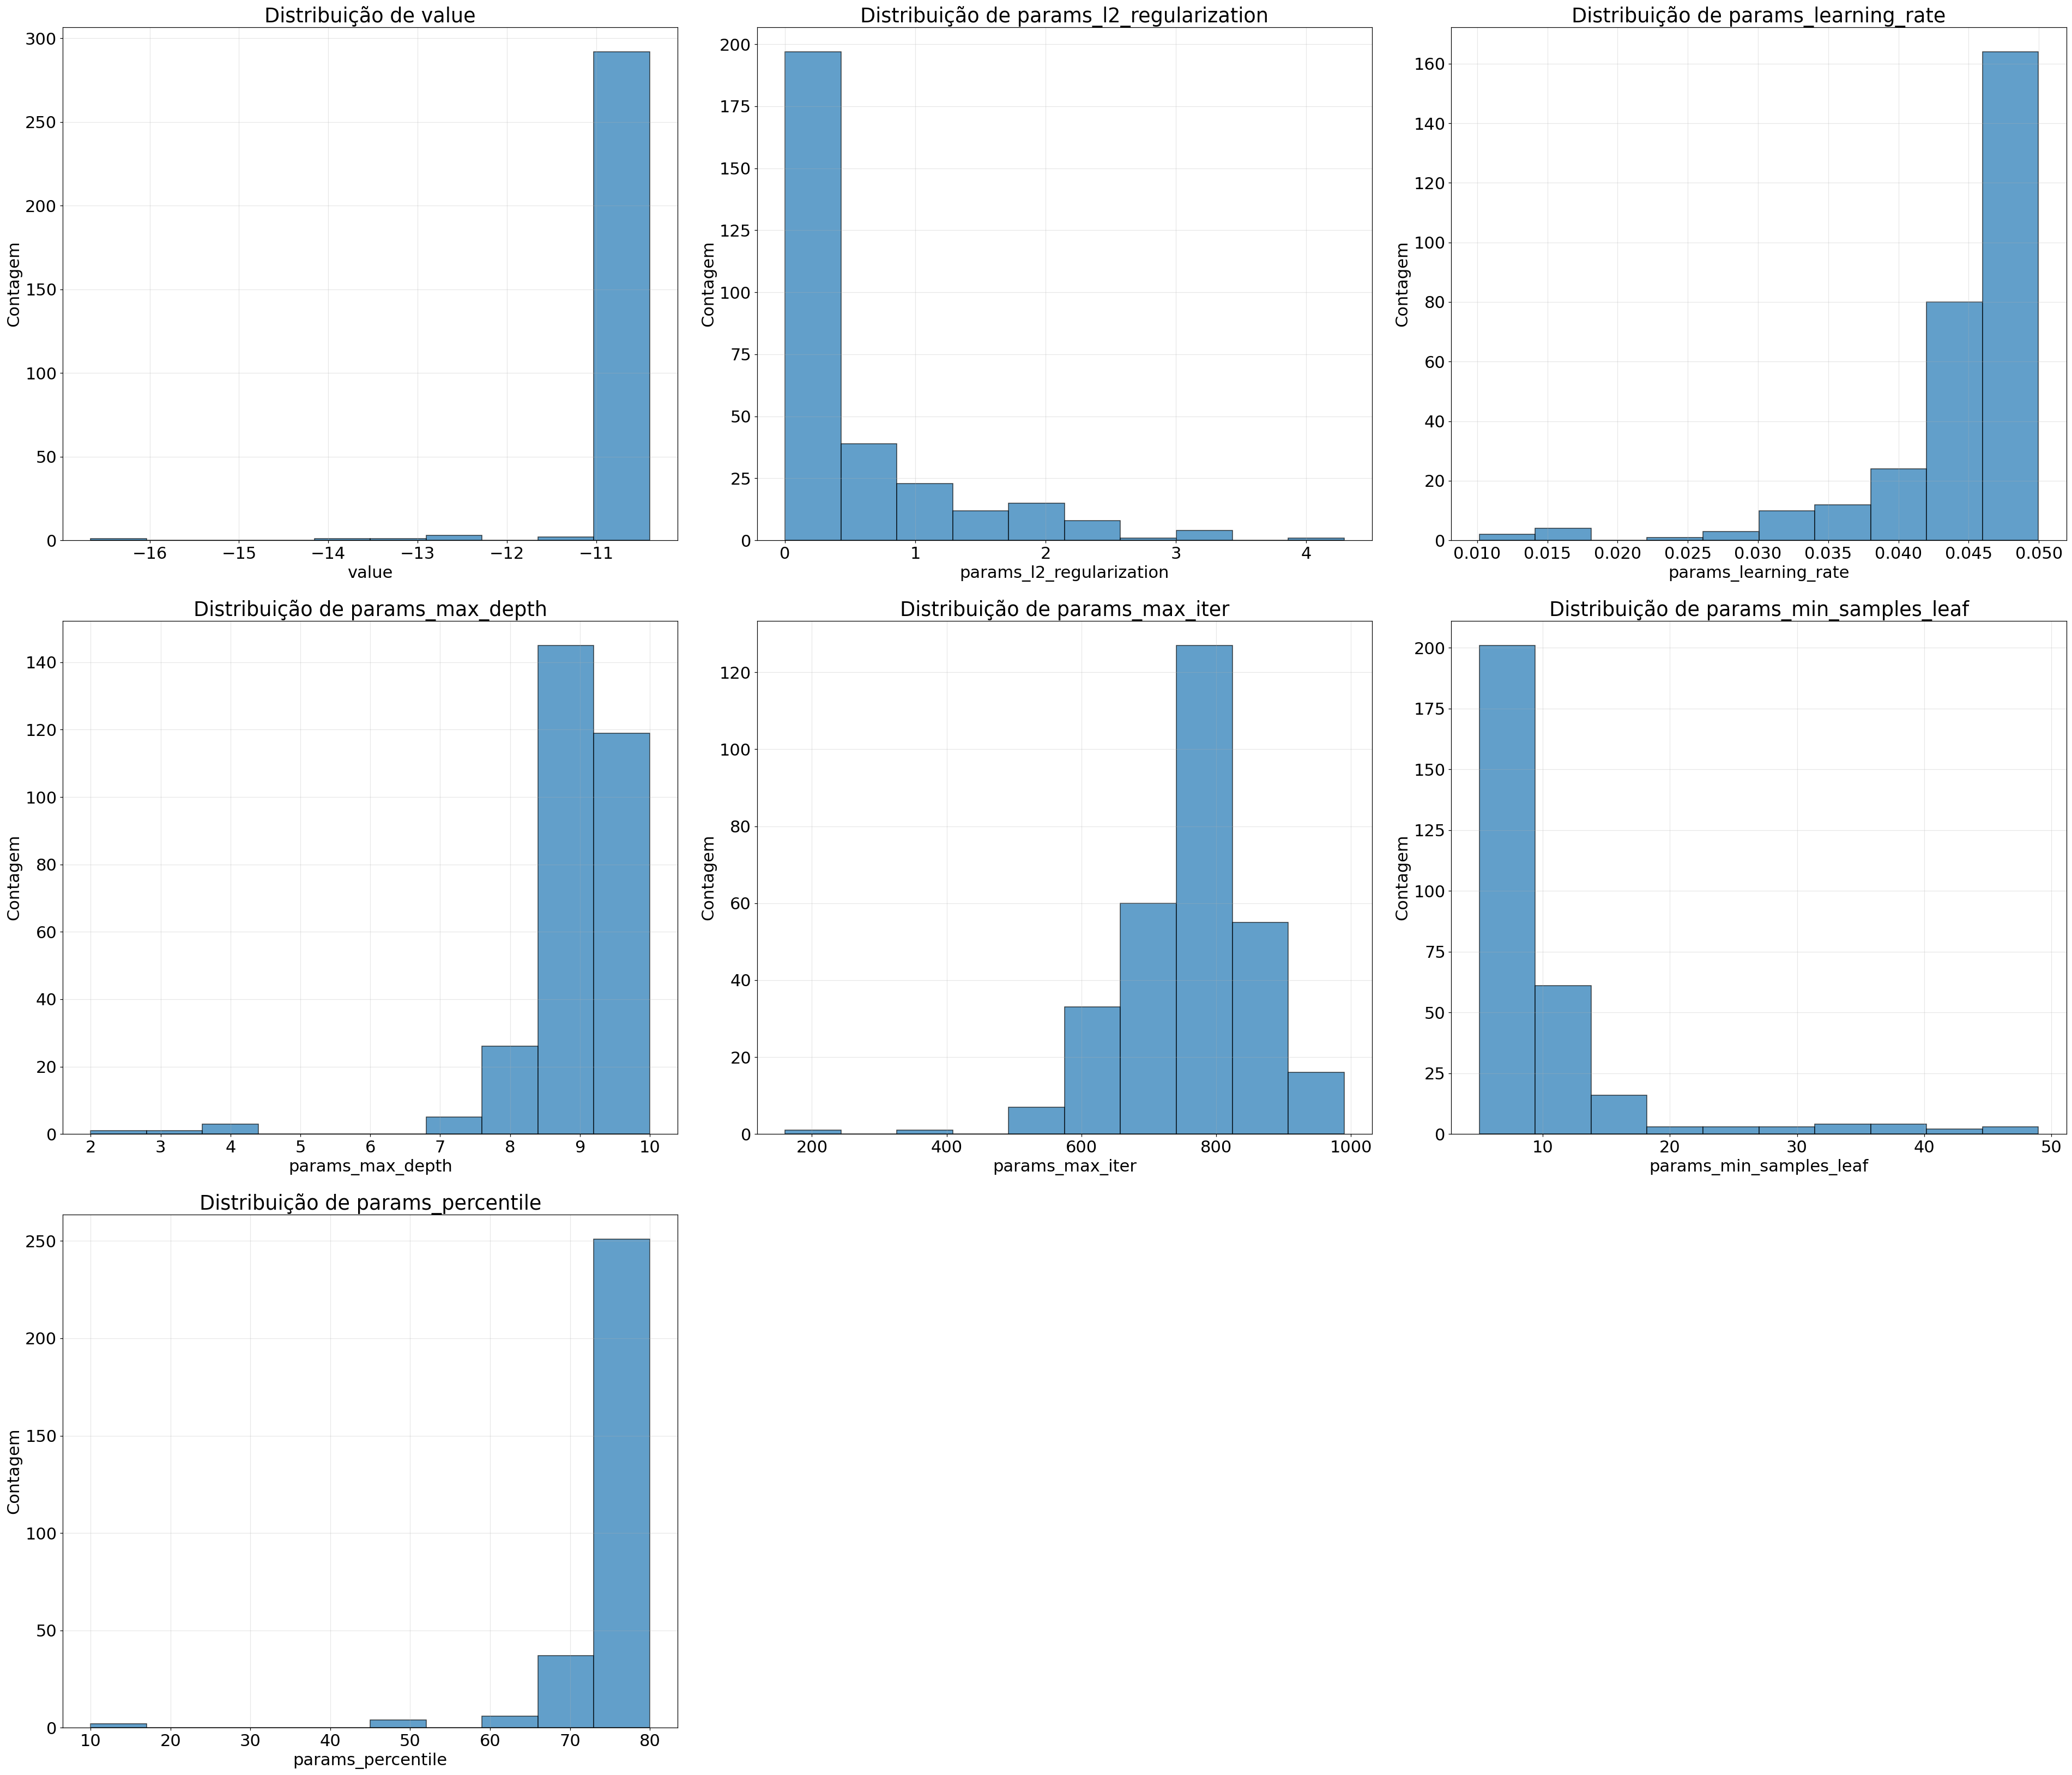

In [73]:
df_hgb = obter_df('HGB_inicial')
plotar(df_hgb)

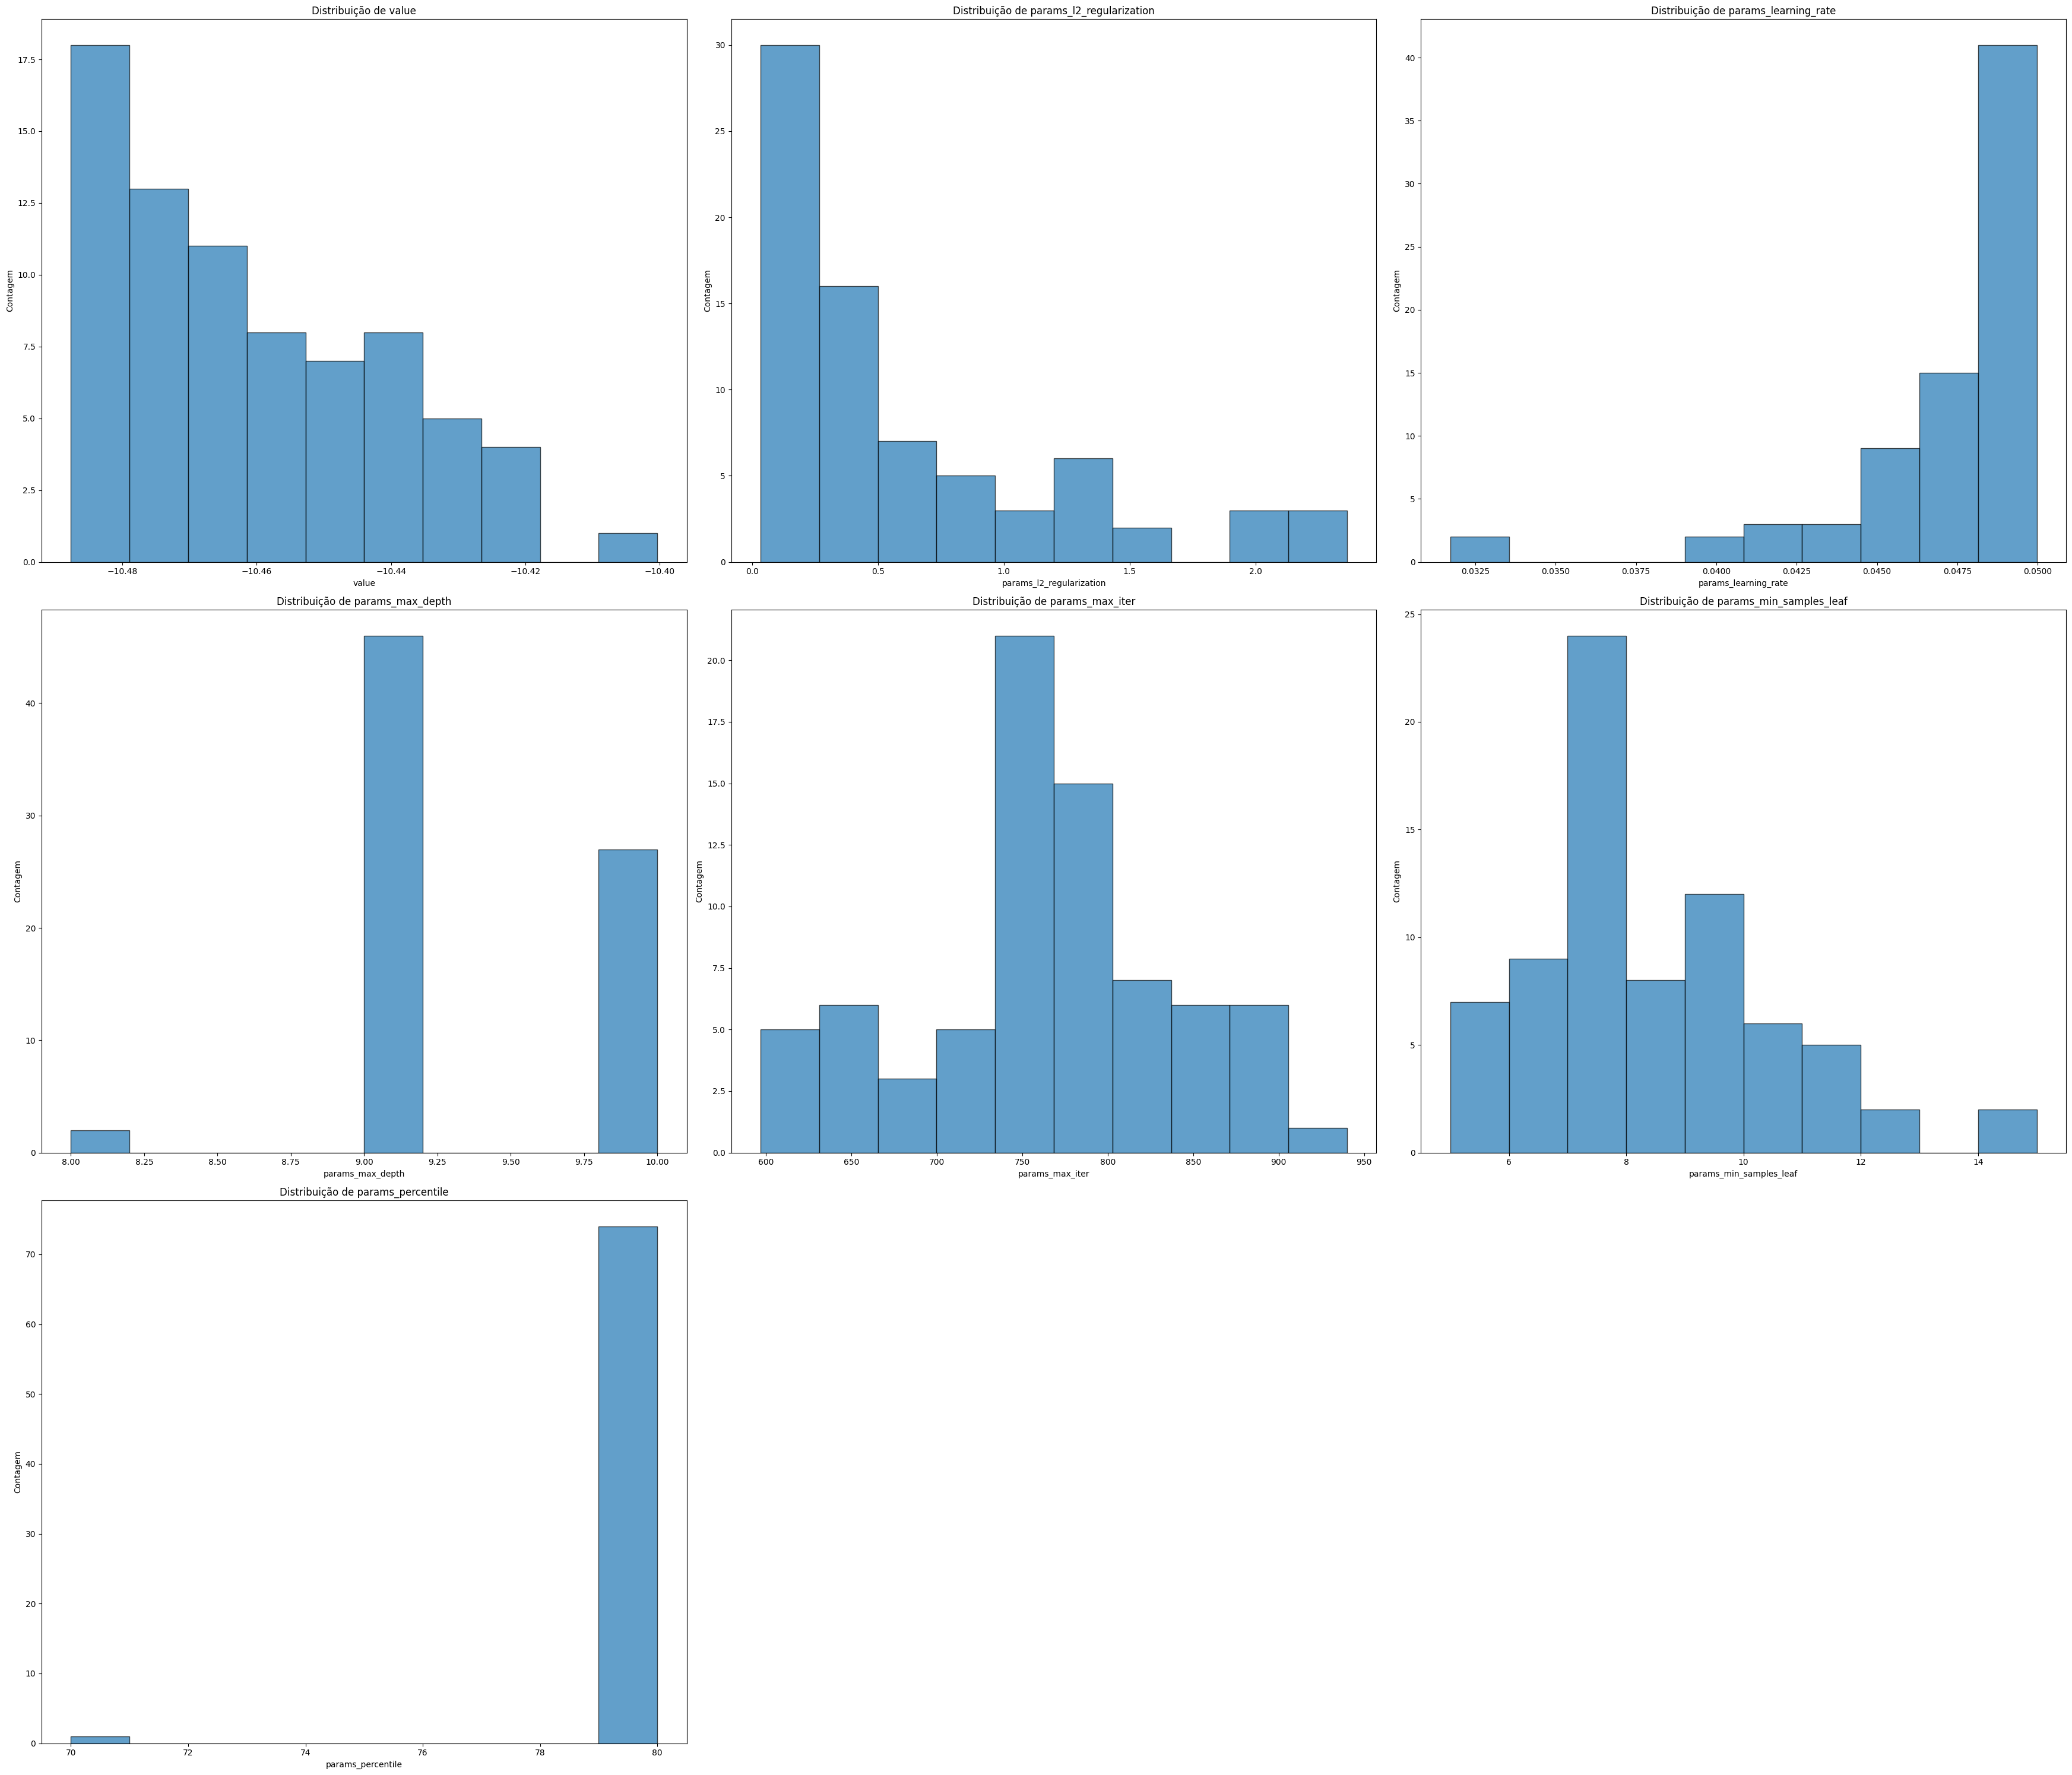

In [121]:
melhores_hgb = melhores_scores(df_hgb)
plotar(melhores_hgb)


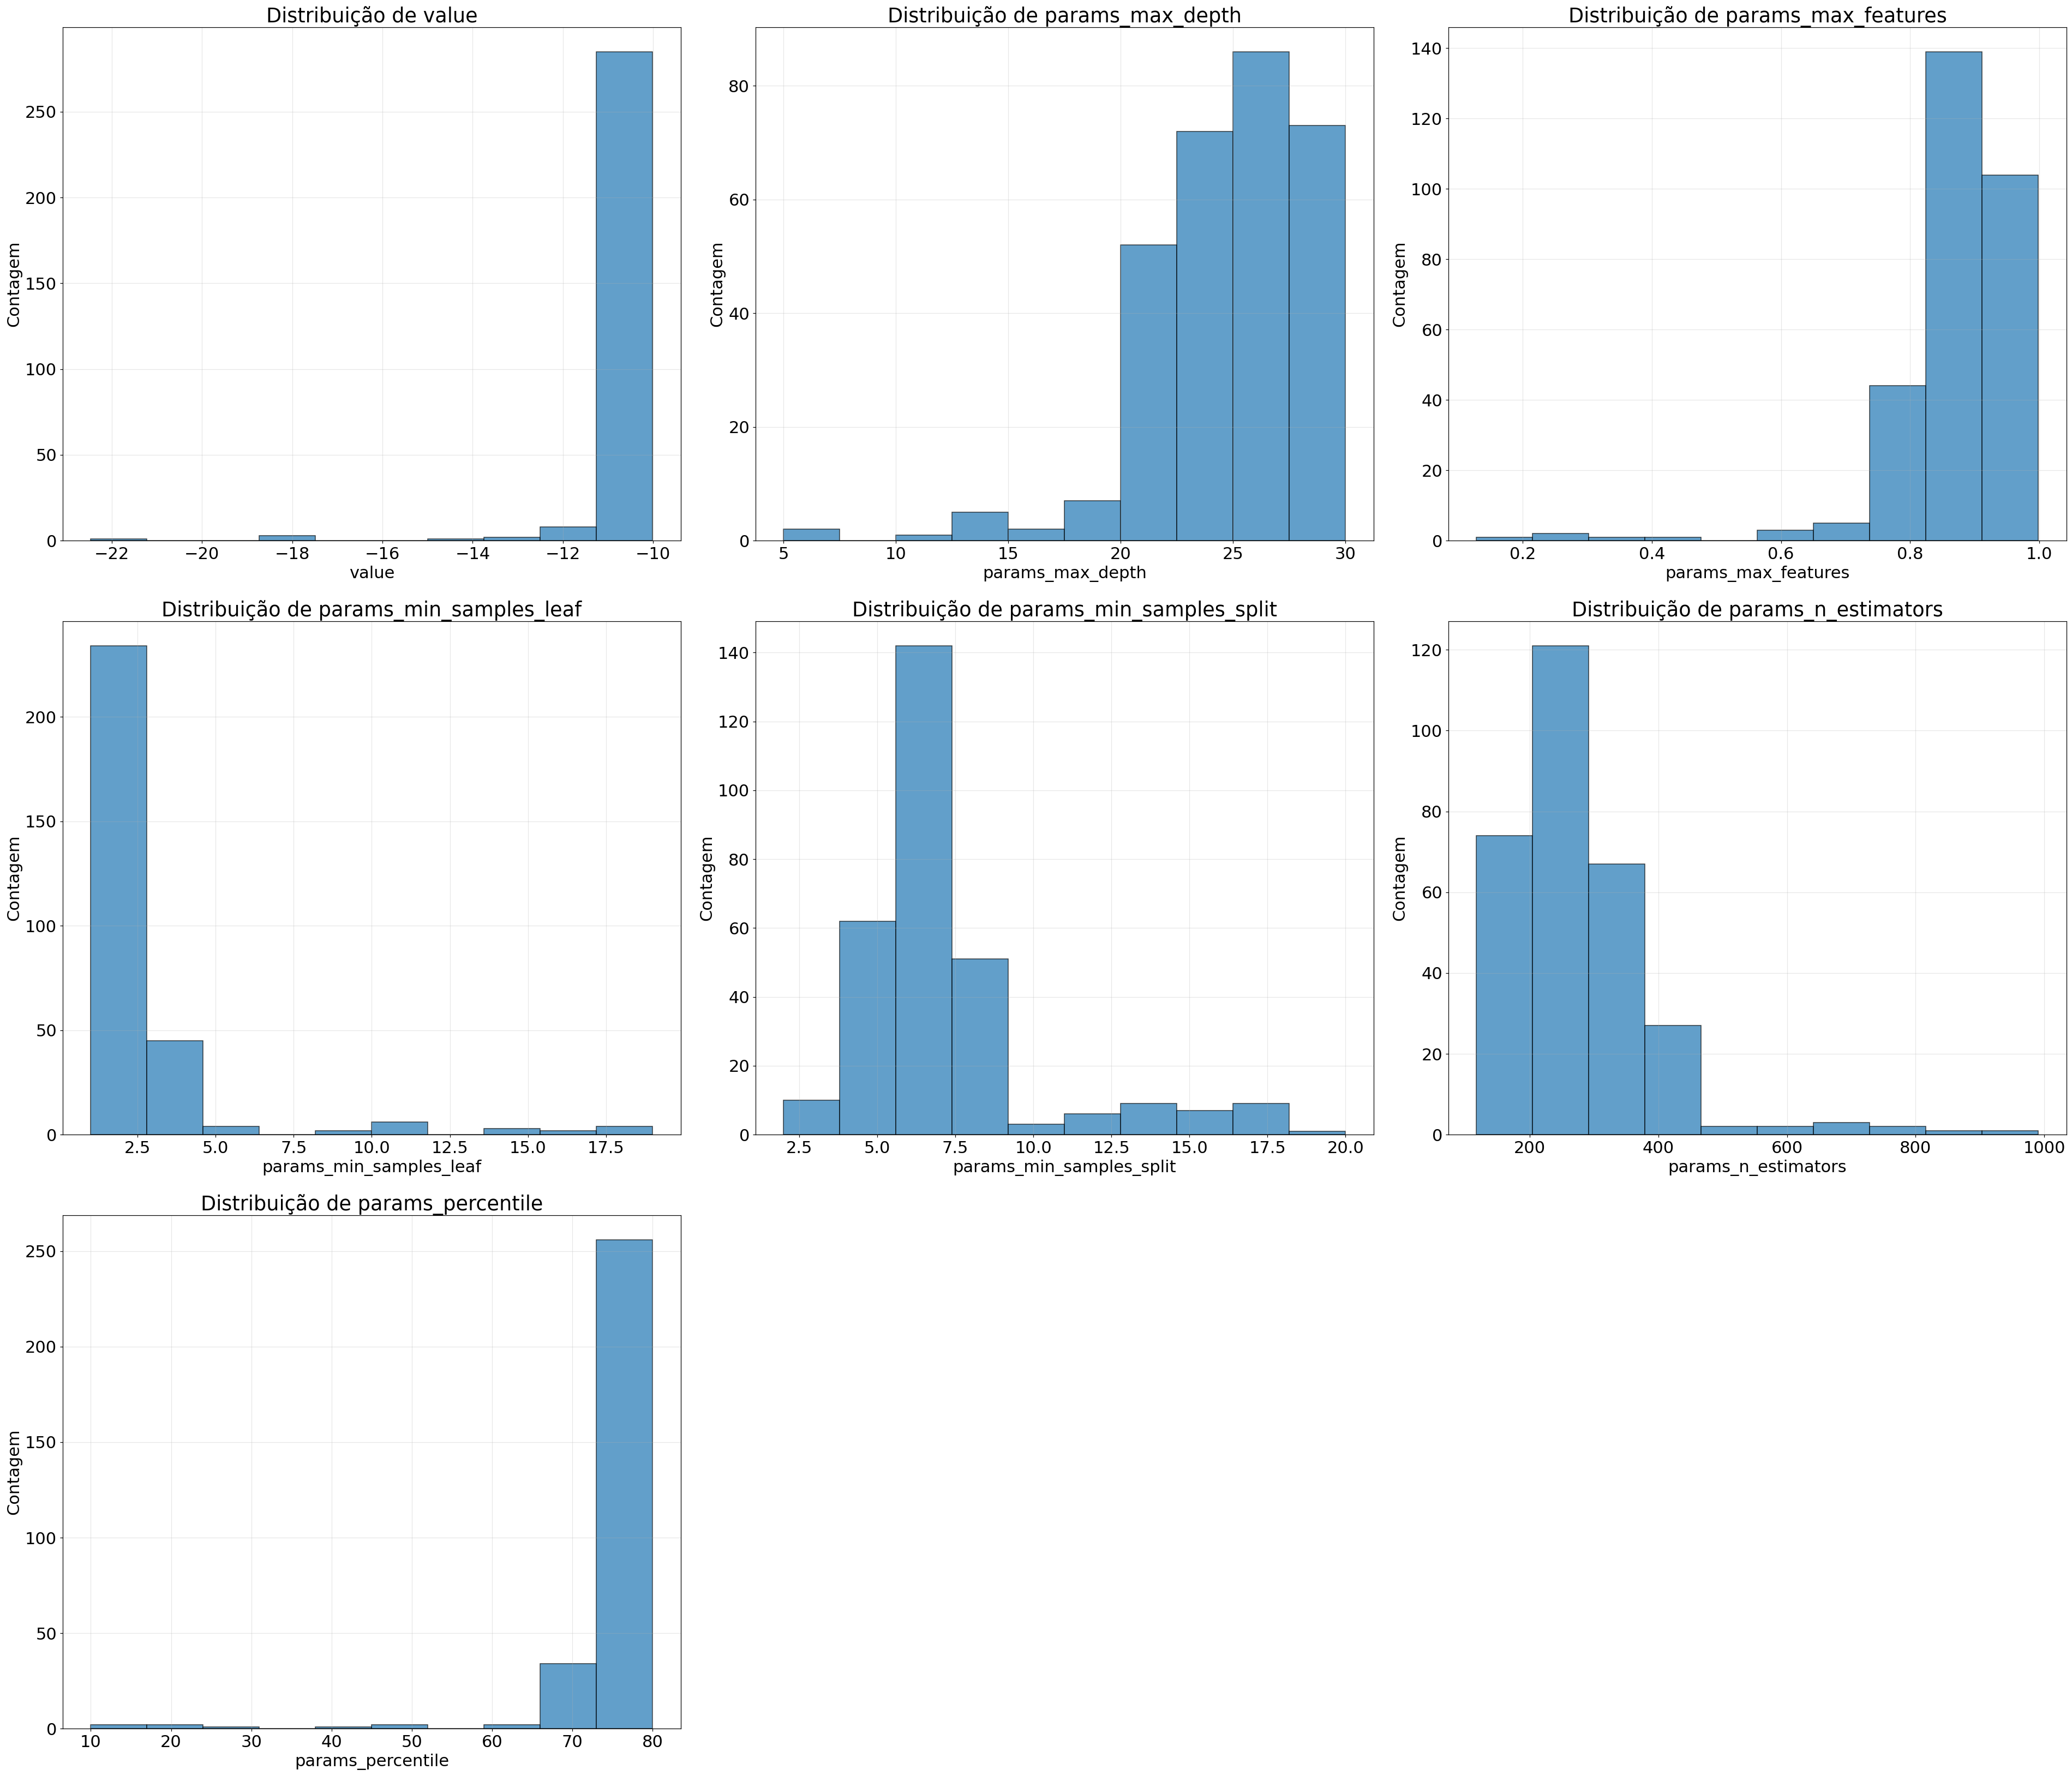

In [74]:
df_ETR = obter_df('ETR_inicial')
plotar(df_ETR)

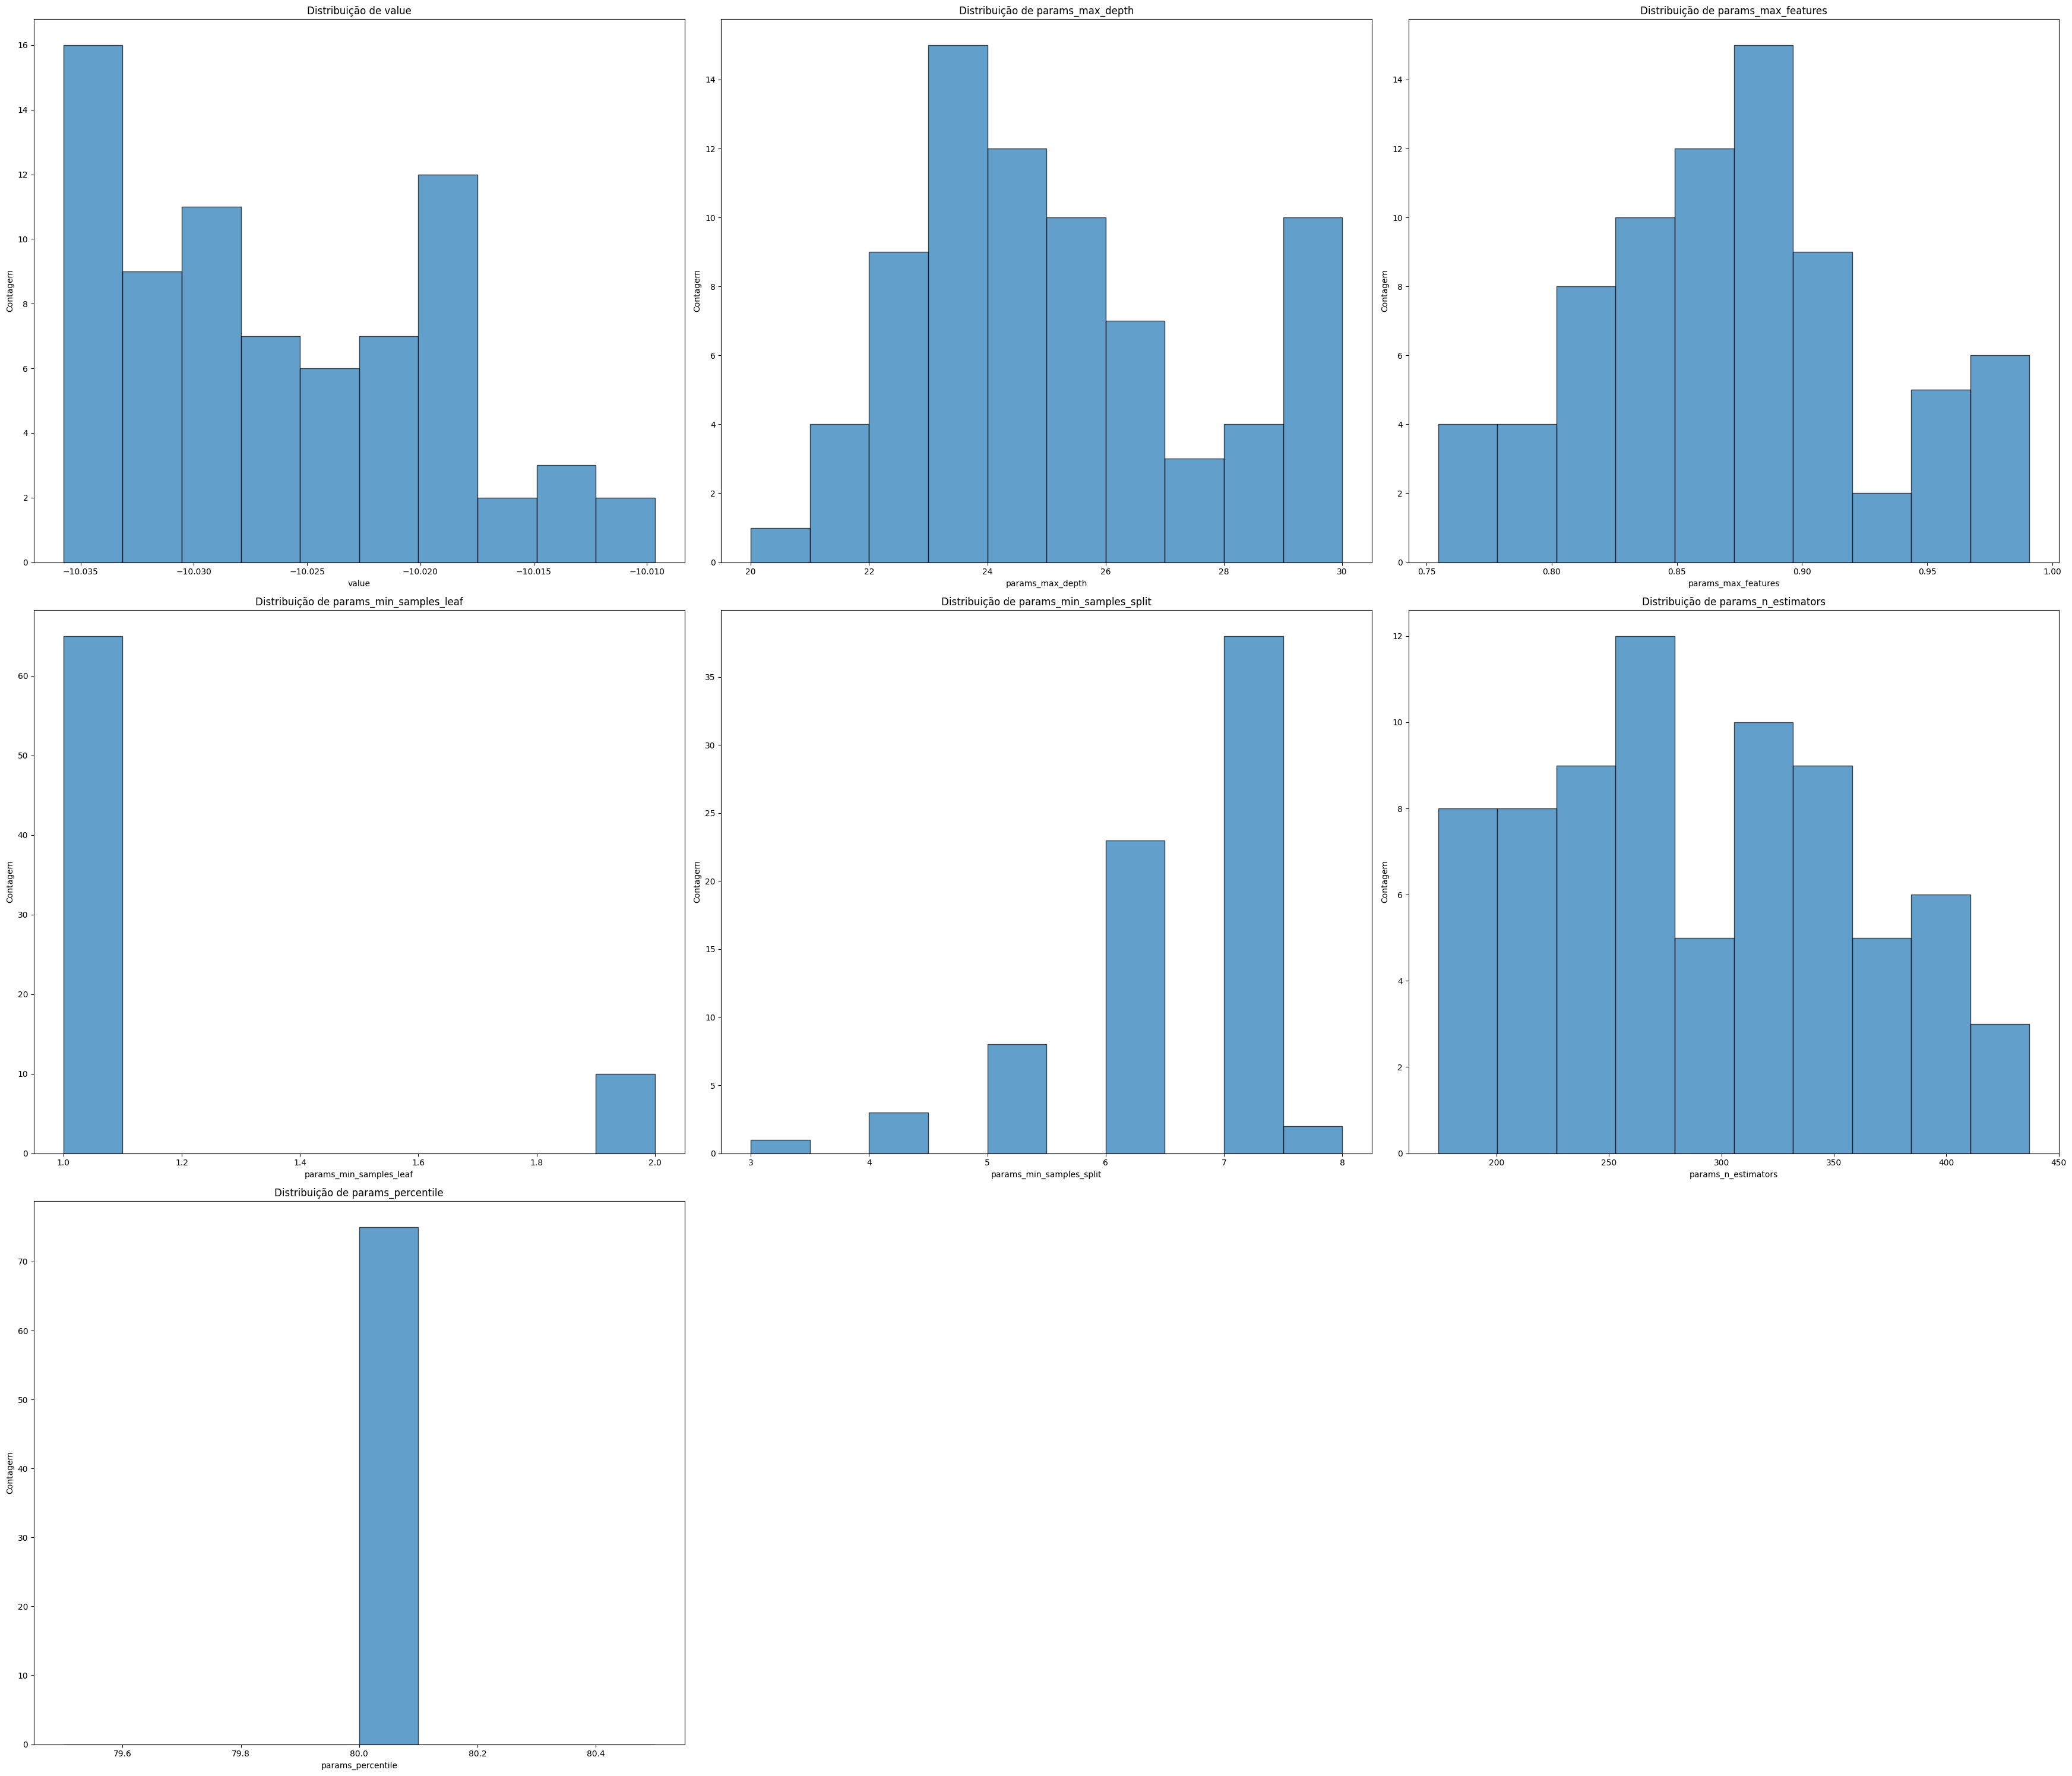

In [117]:
melhores_ETR = melhores_scores(df_ETR)
plotar(melhores_ETR, salvar=True, arquivo='ETR_inicial_mel')

Redução de dimensionalidade não foi uma boa. A versão inicial pegava a dimensionalidade de 10% dos atributos originais até 80%. No fim, quanto maior era o percentil, melhor o desempenho.

## Ciclo 2

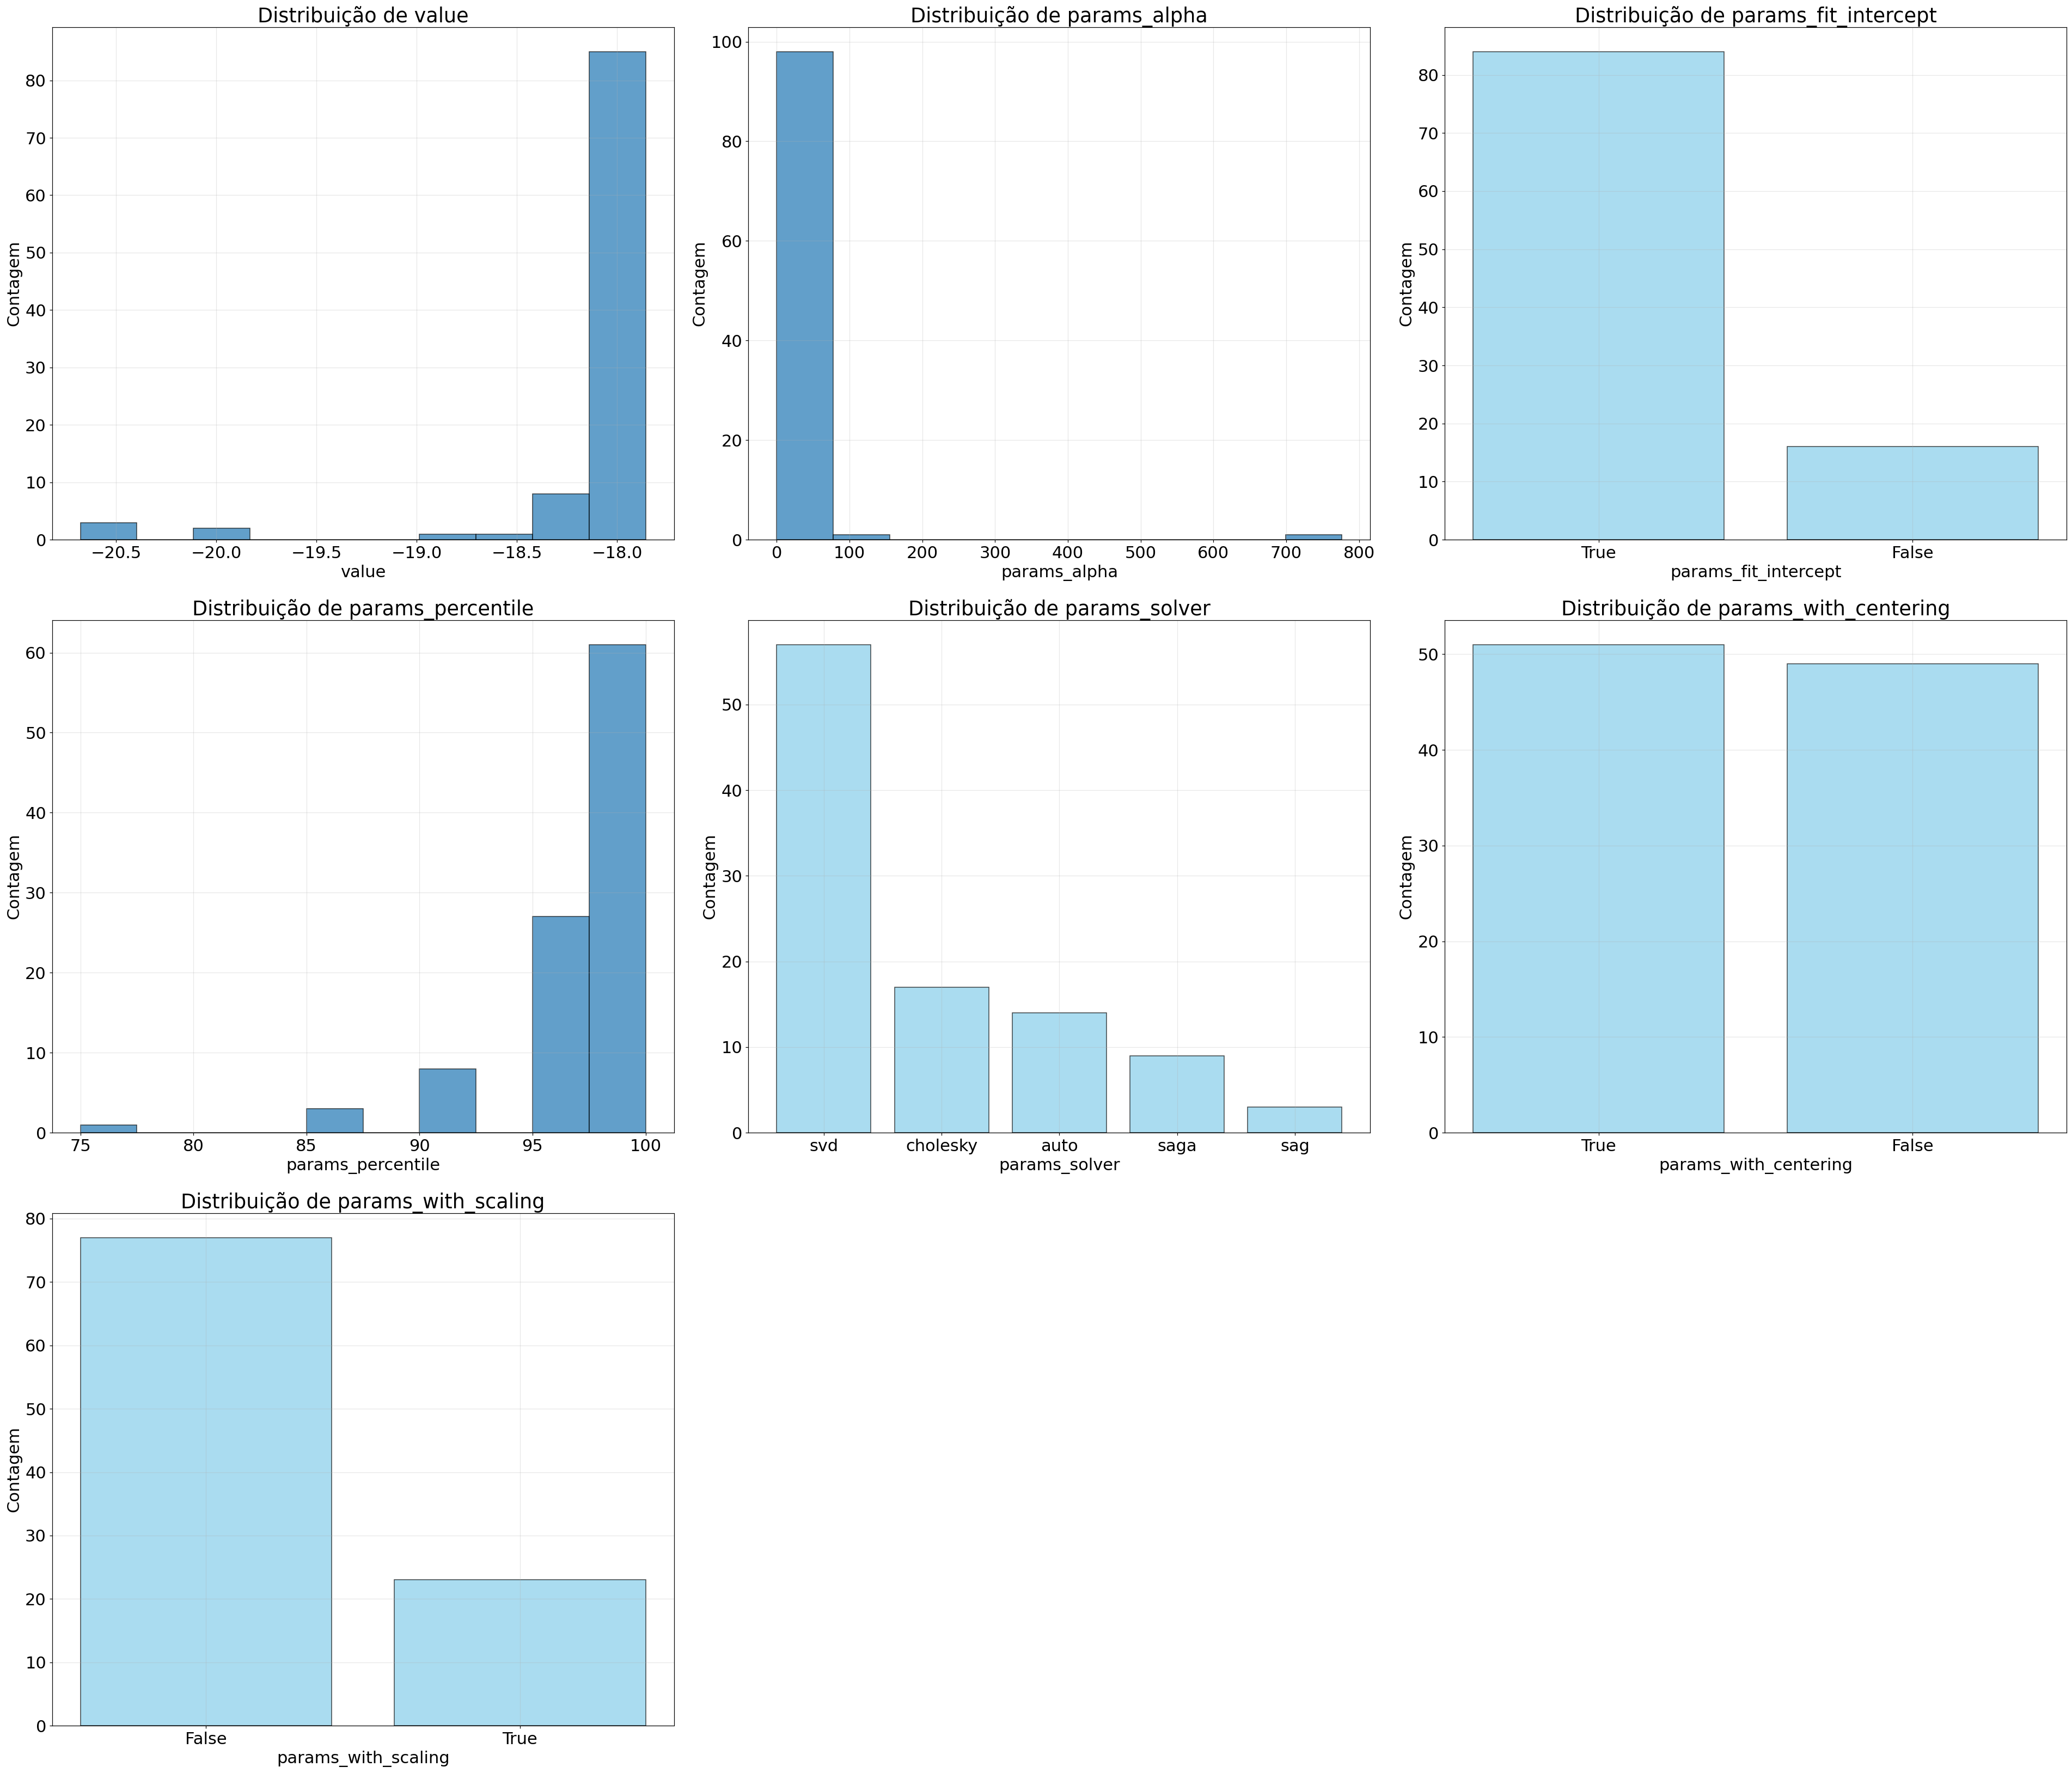

In [75]:
df_ridge = obter_df('RIDGE_inicial')
plotar(df_ridge)

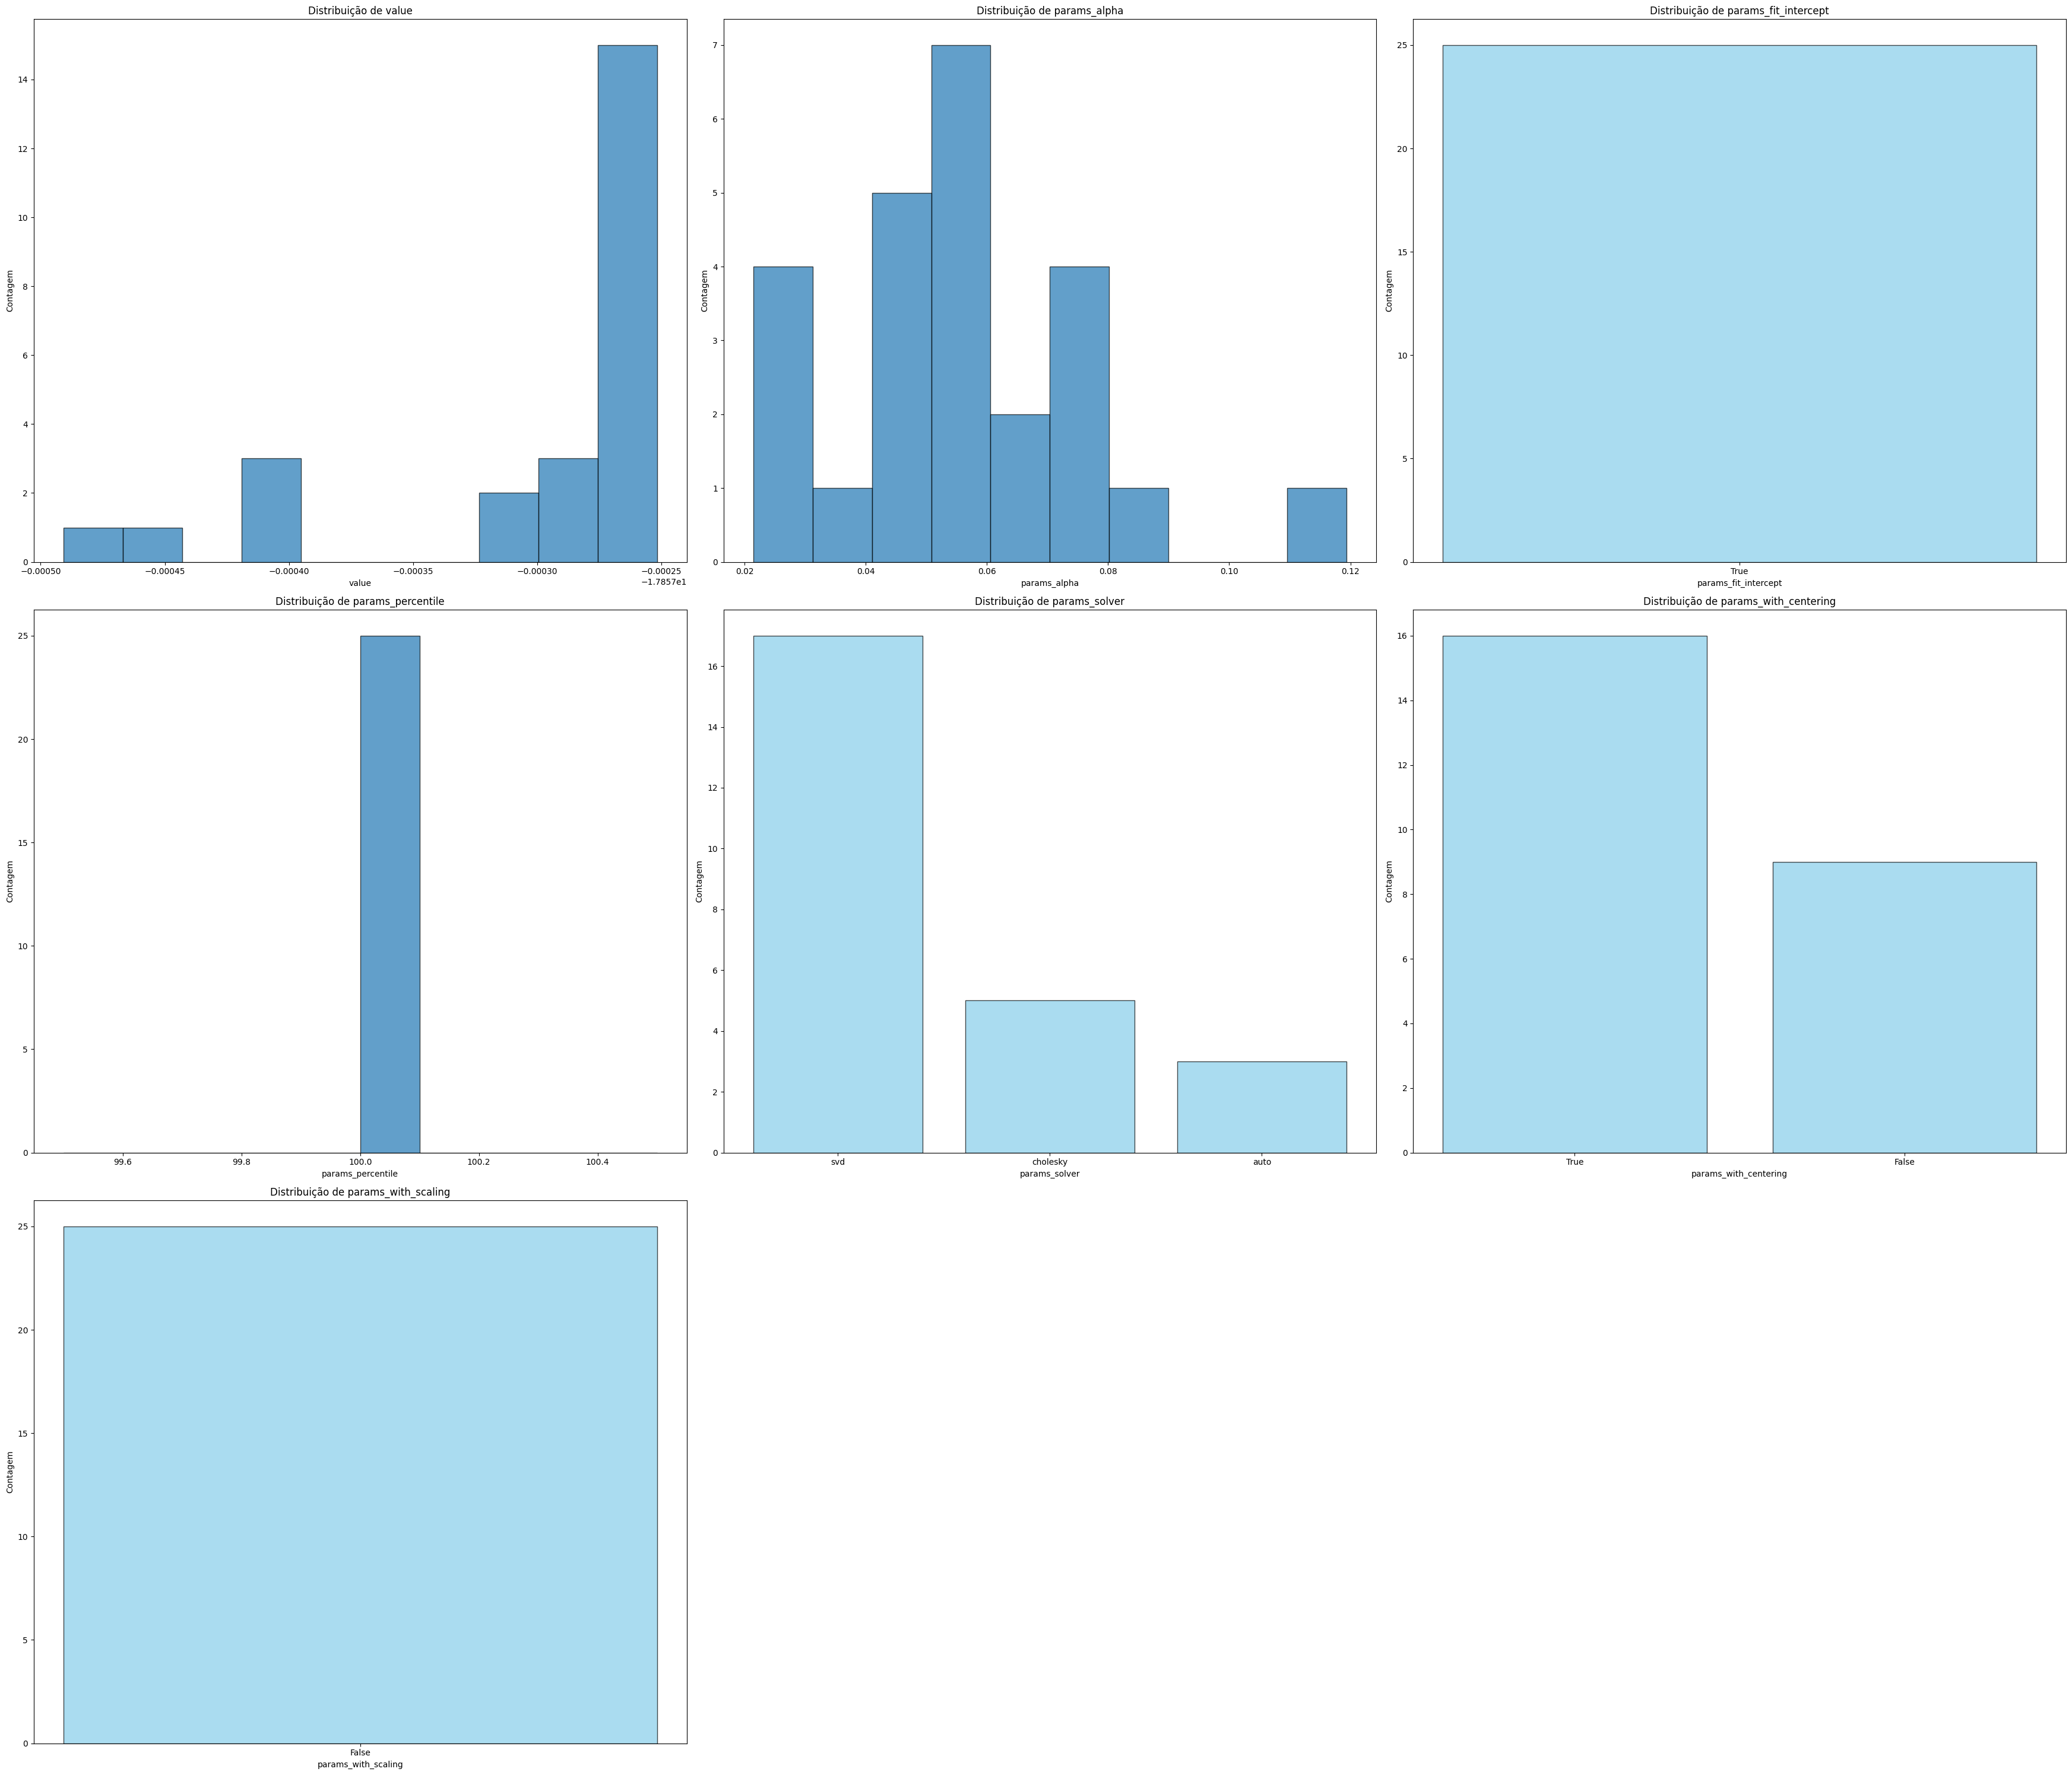

In [19]:
melhores_ridge = melhores_scores(df_ridge)
plotar(melhores_ridge, salvar=True, arquivo='RIDGE_inicial.png')

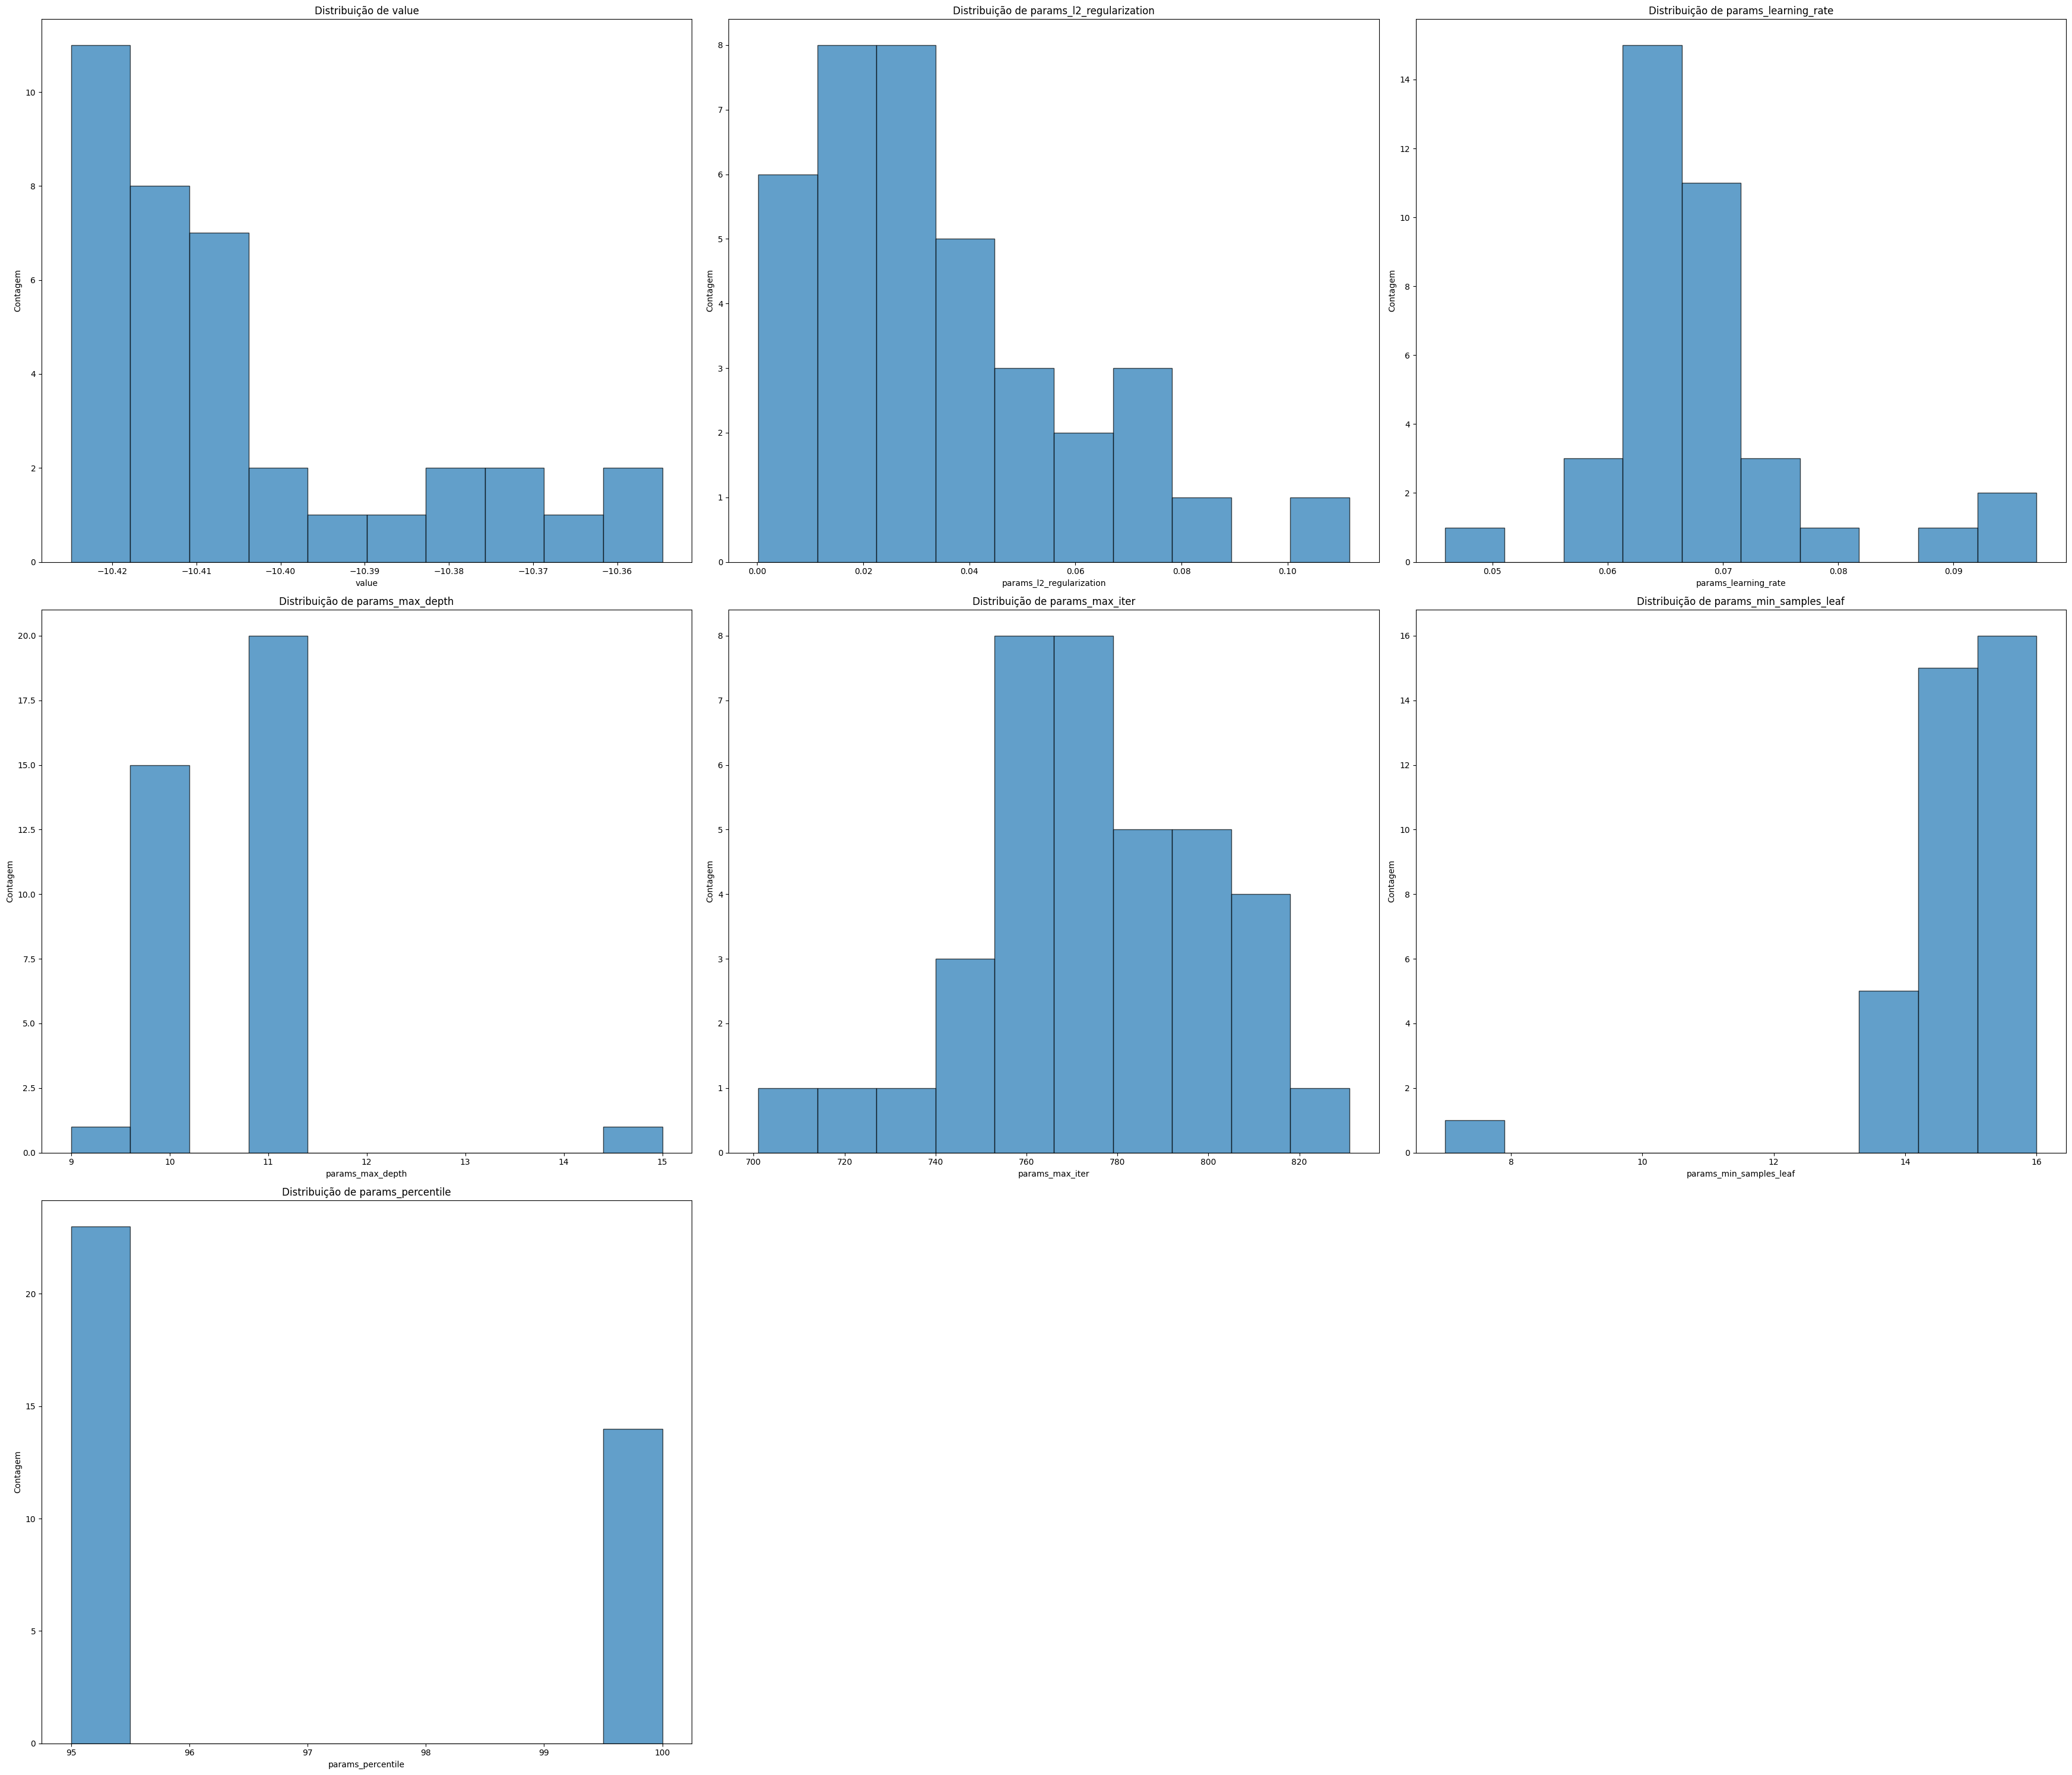

In [ ]:
ciclo('melhorando_HGB')

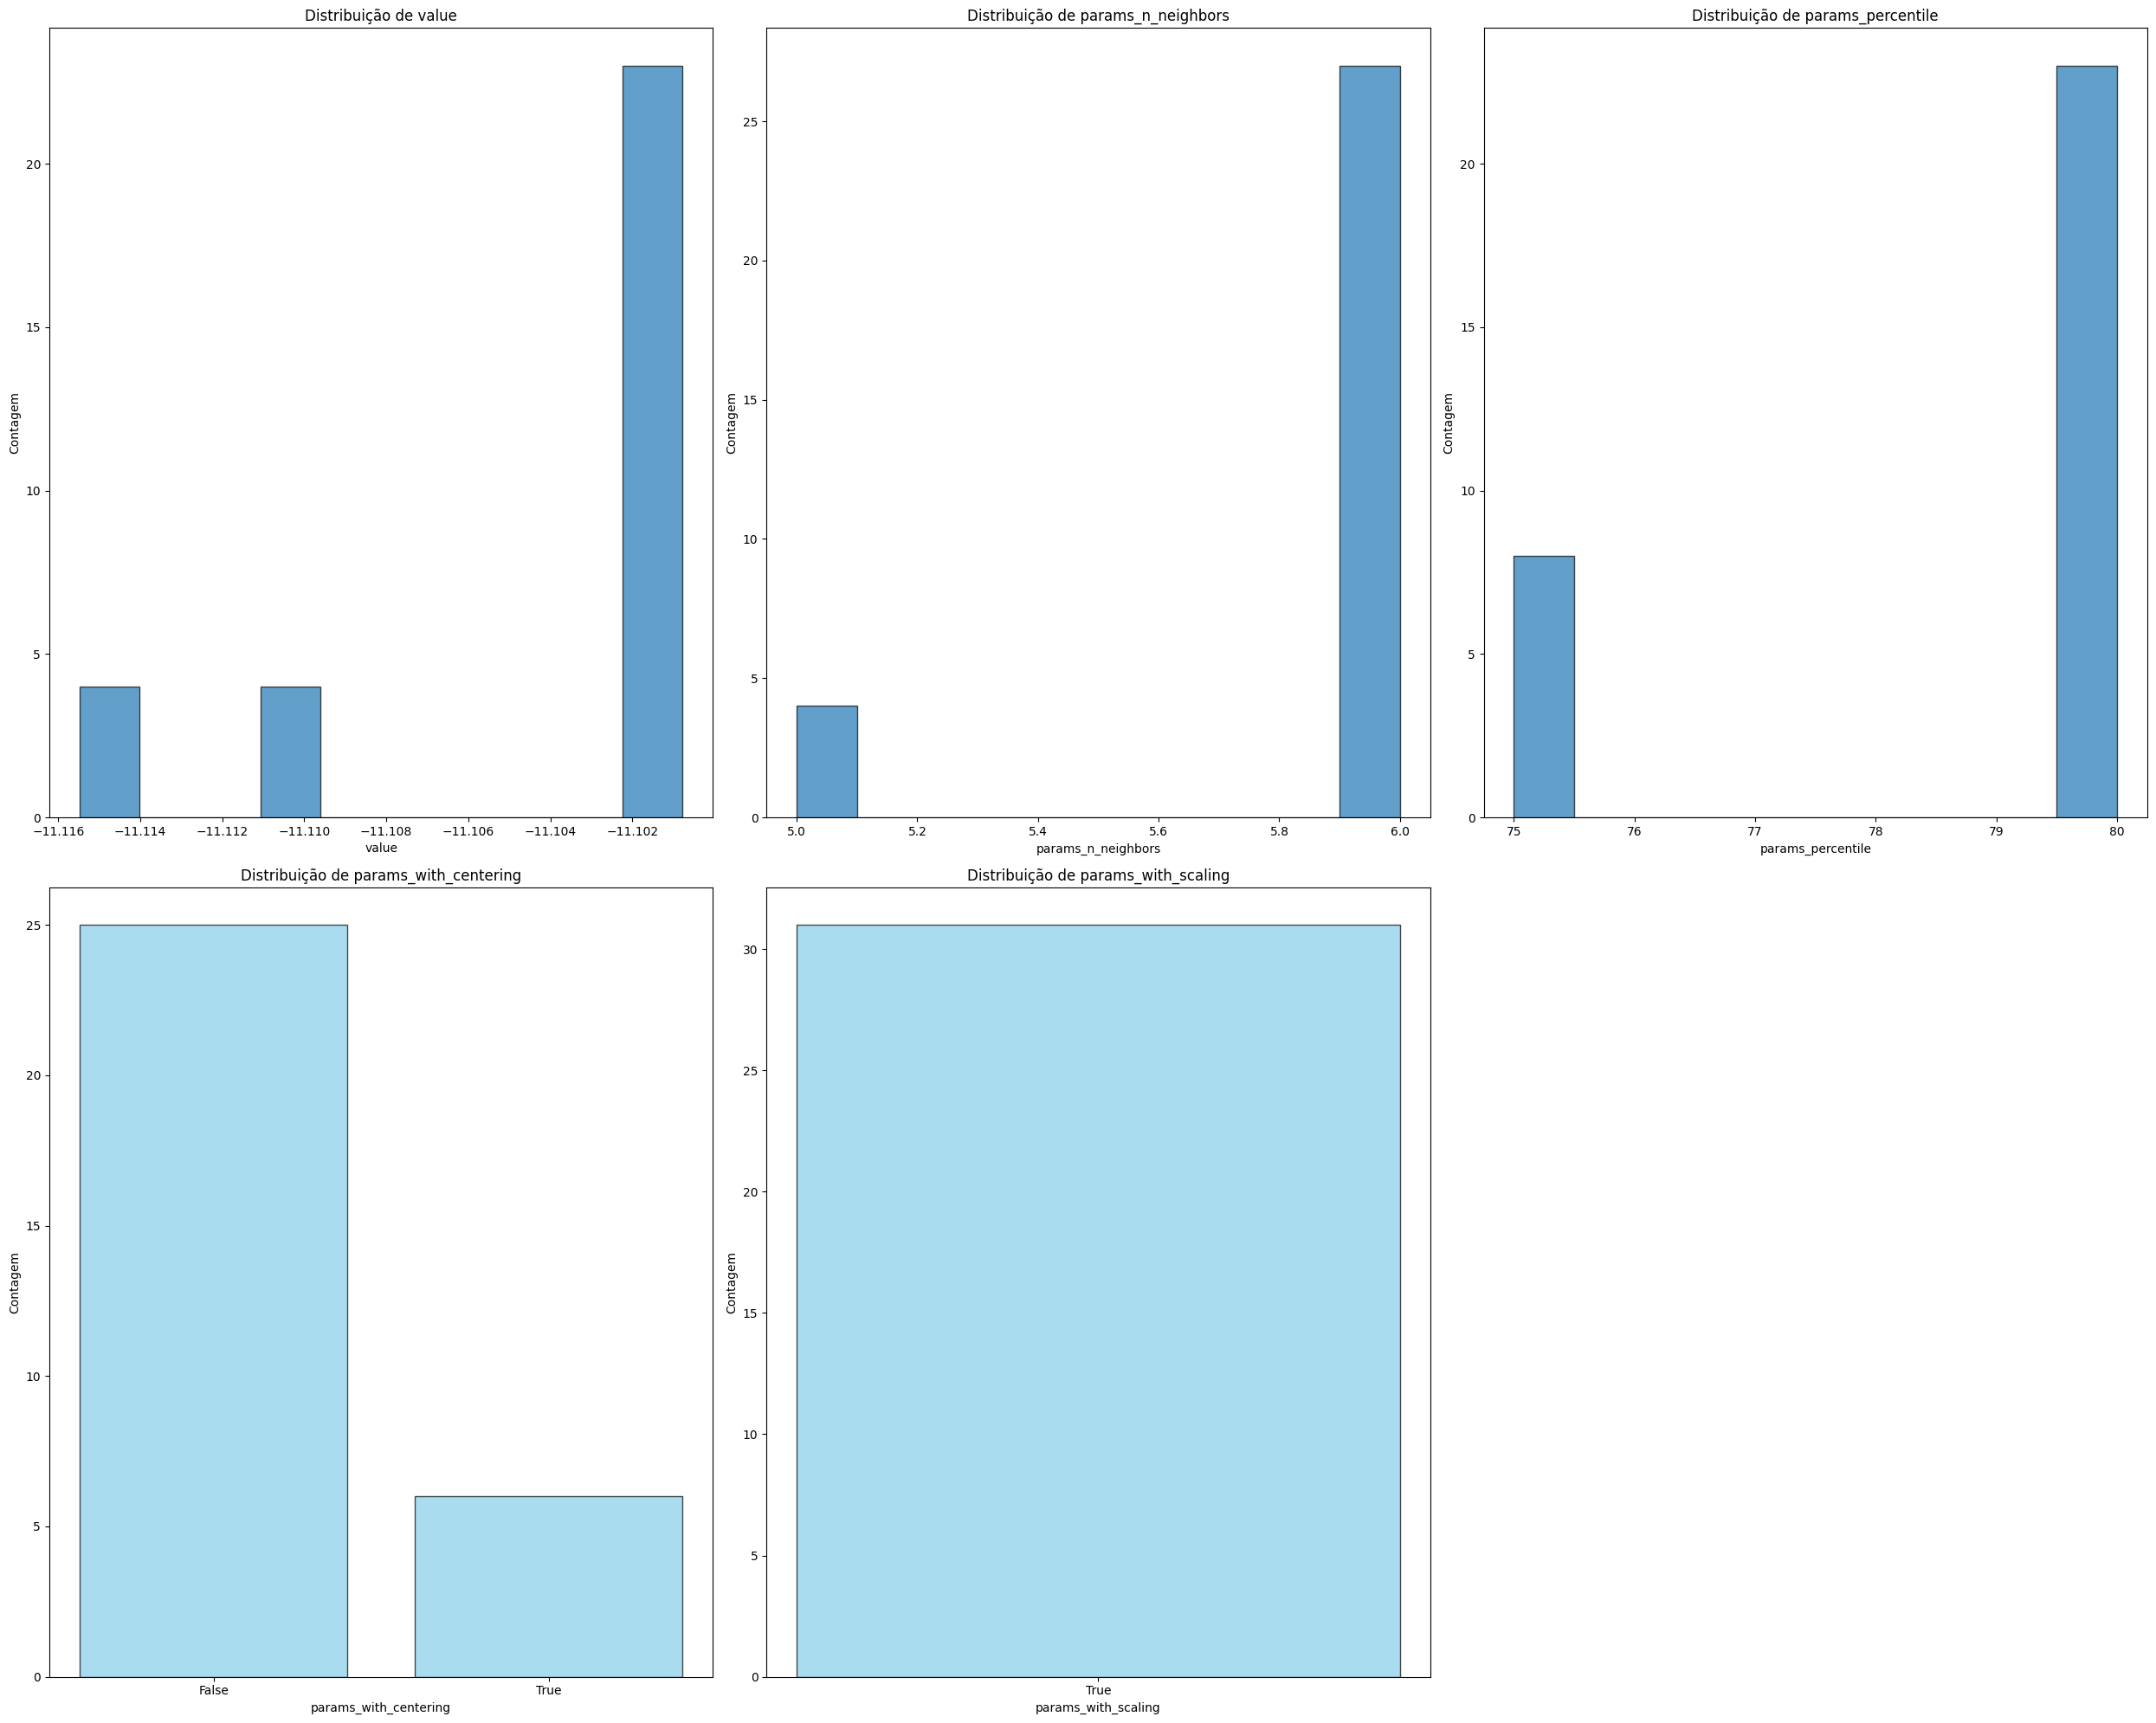

In [ ]:
ciclo('melhorando_KNN')

## Ciclo 3

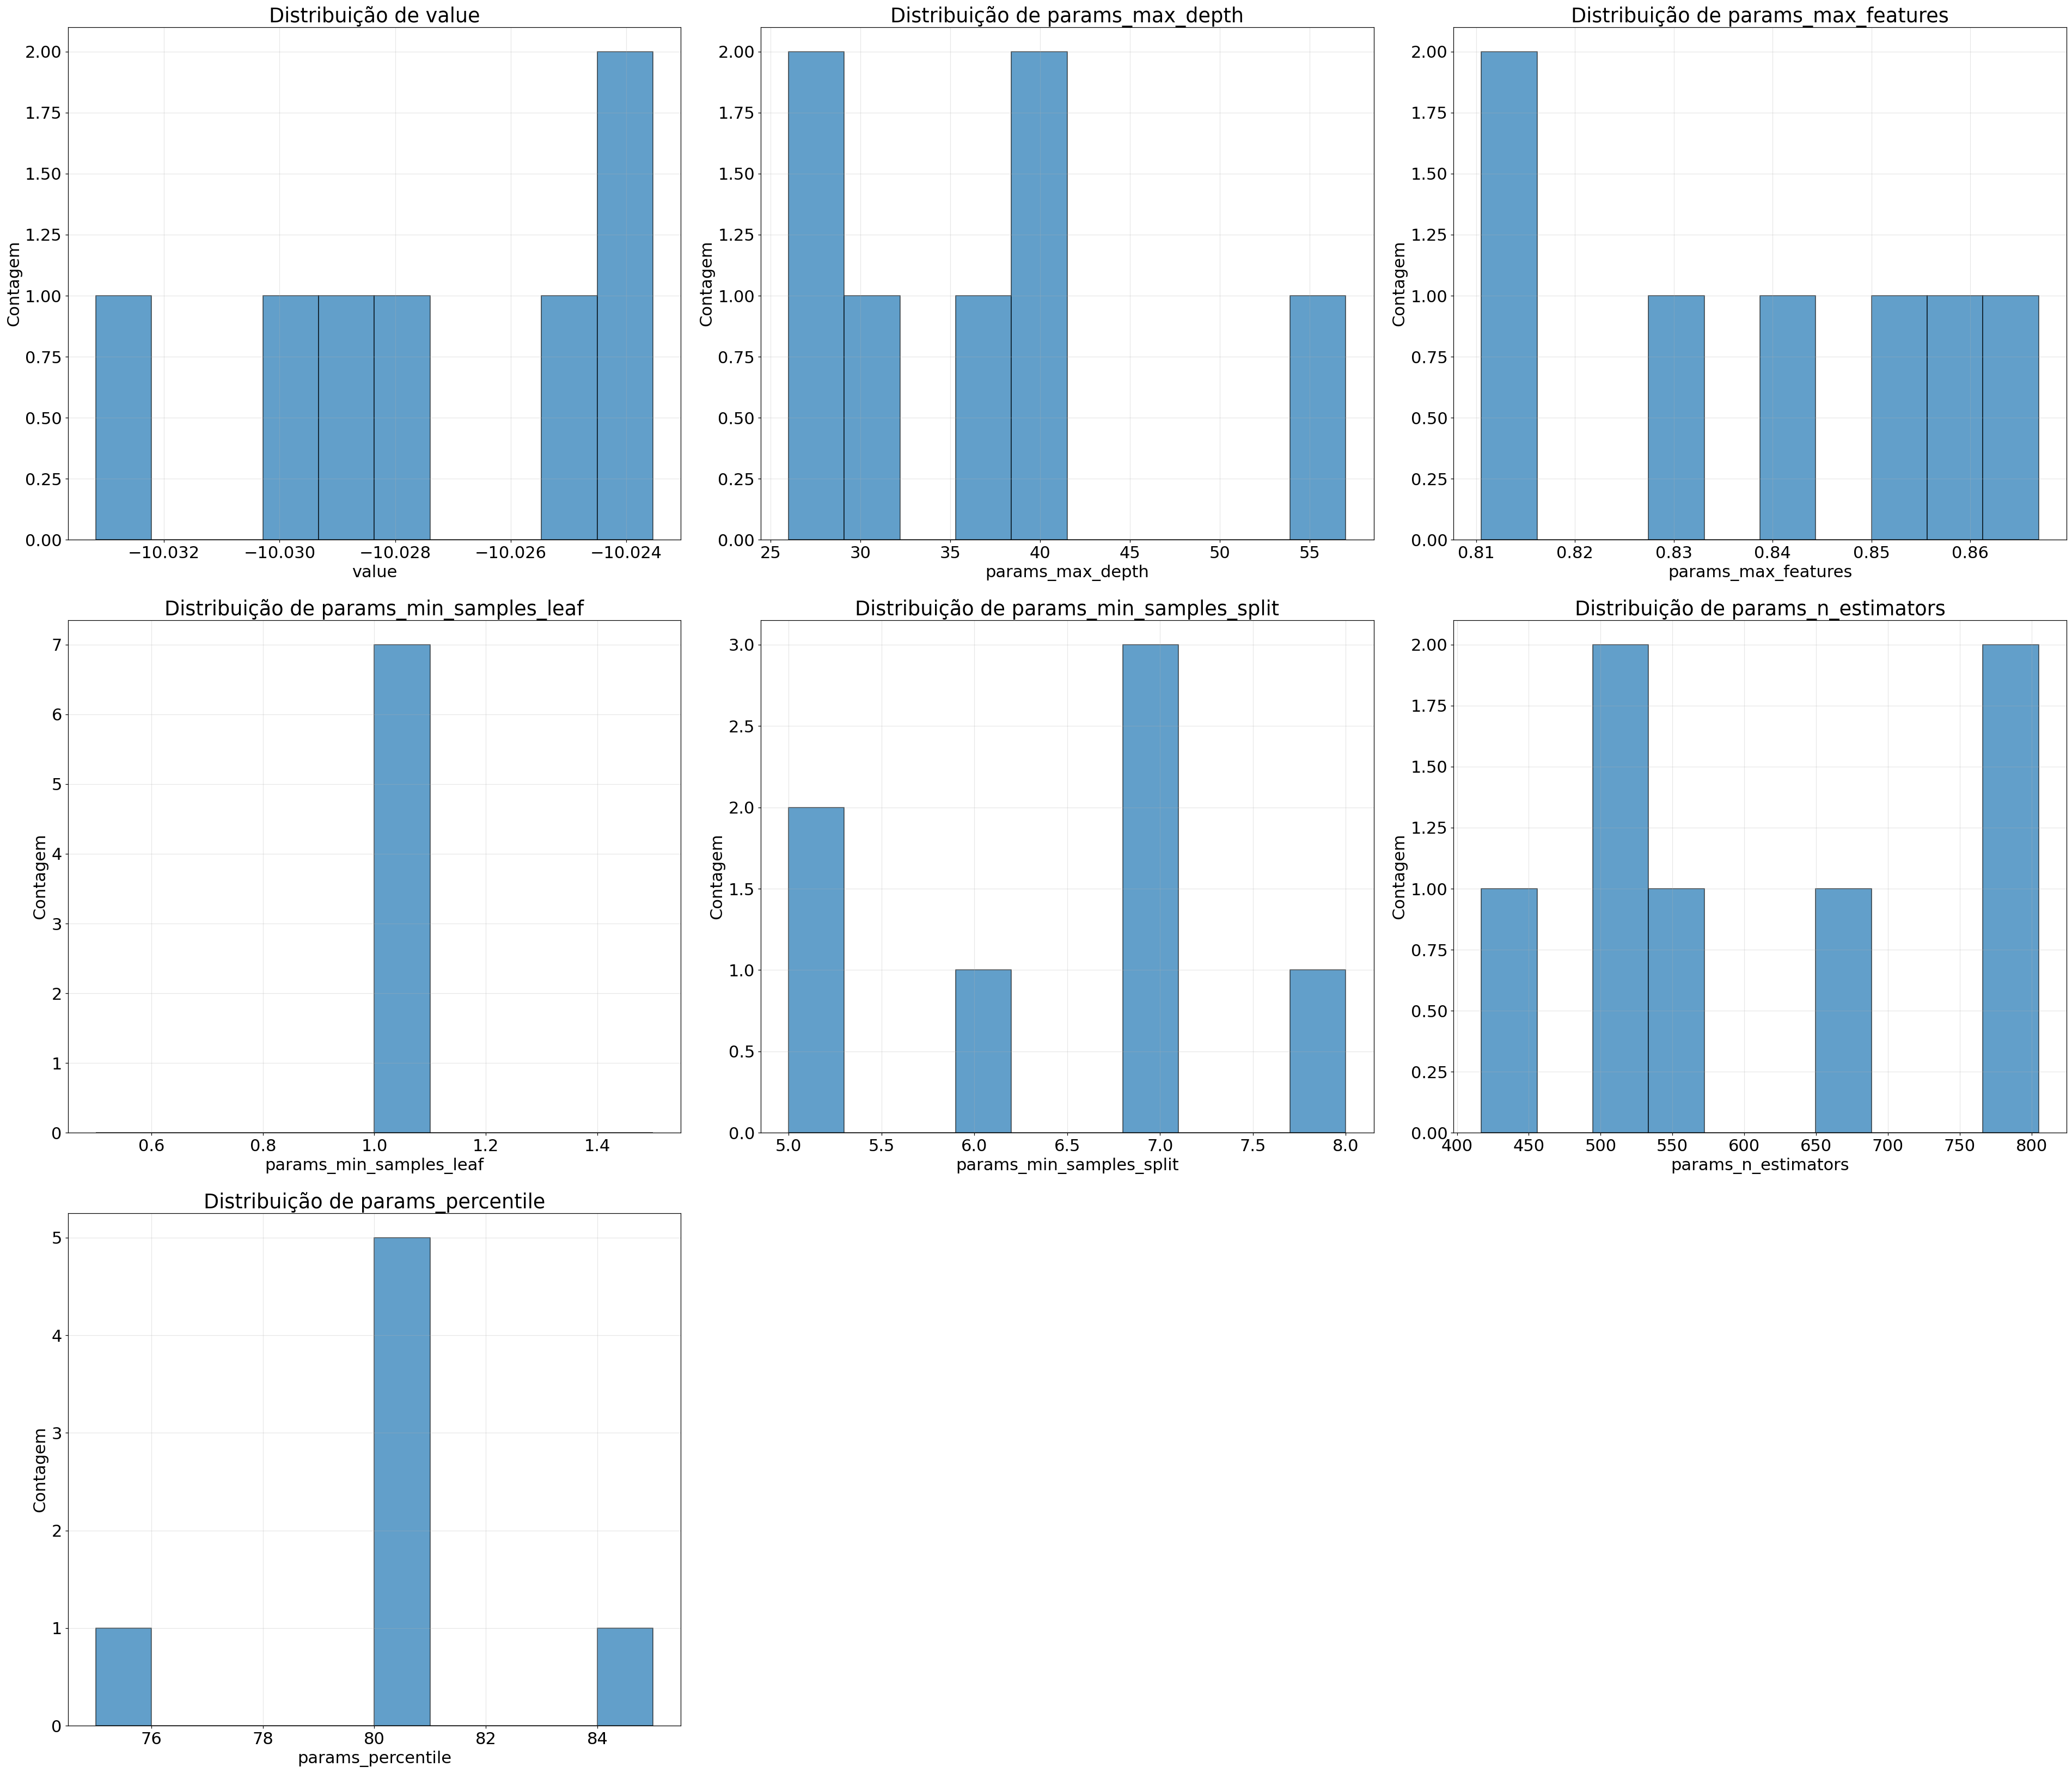

In [77]:
df_ETR = obter_df('ETR_ciclo2')
melhores_ETR = melhores_scores(df_ETR)
plotar(melhores_ETR)

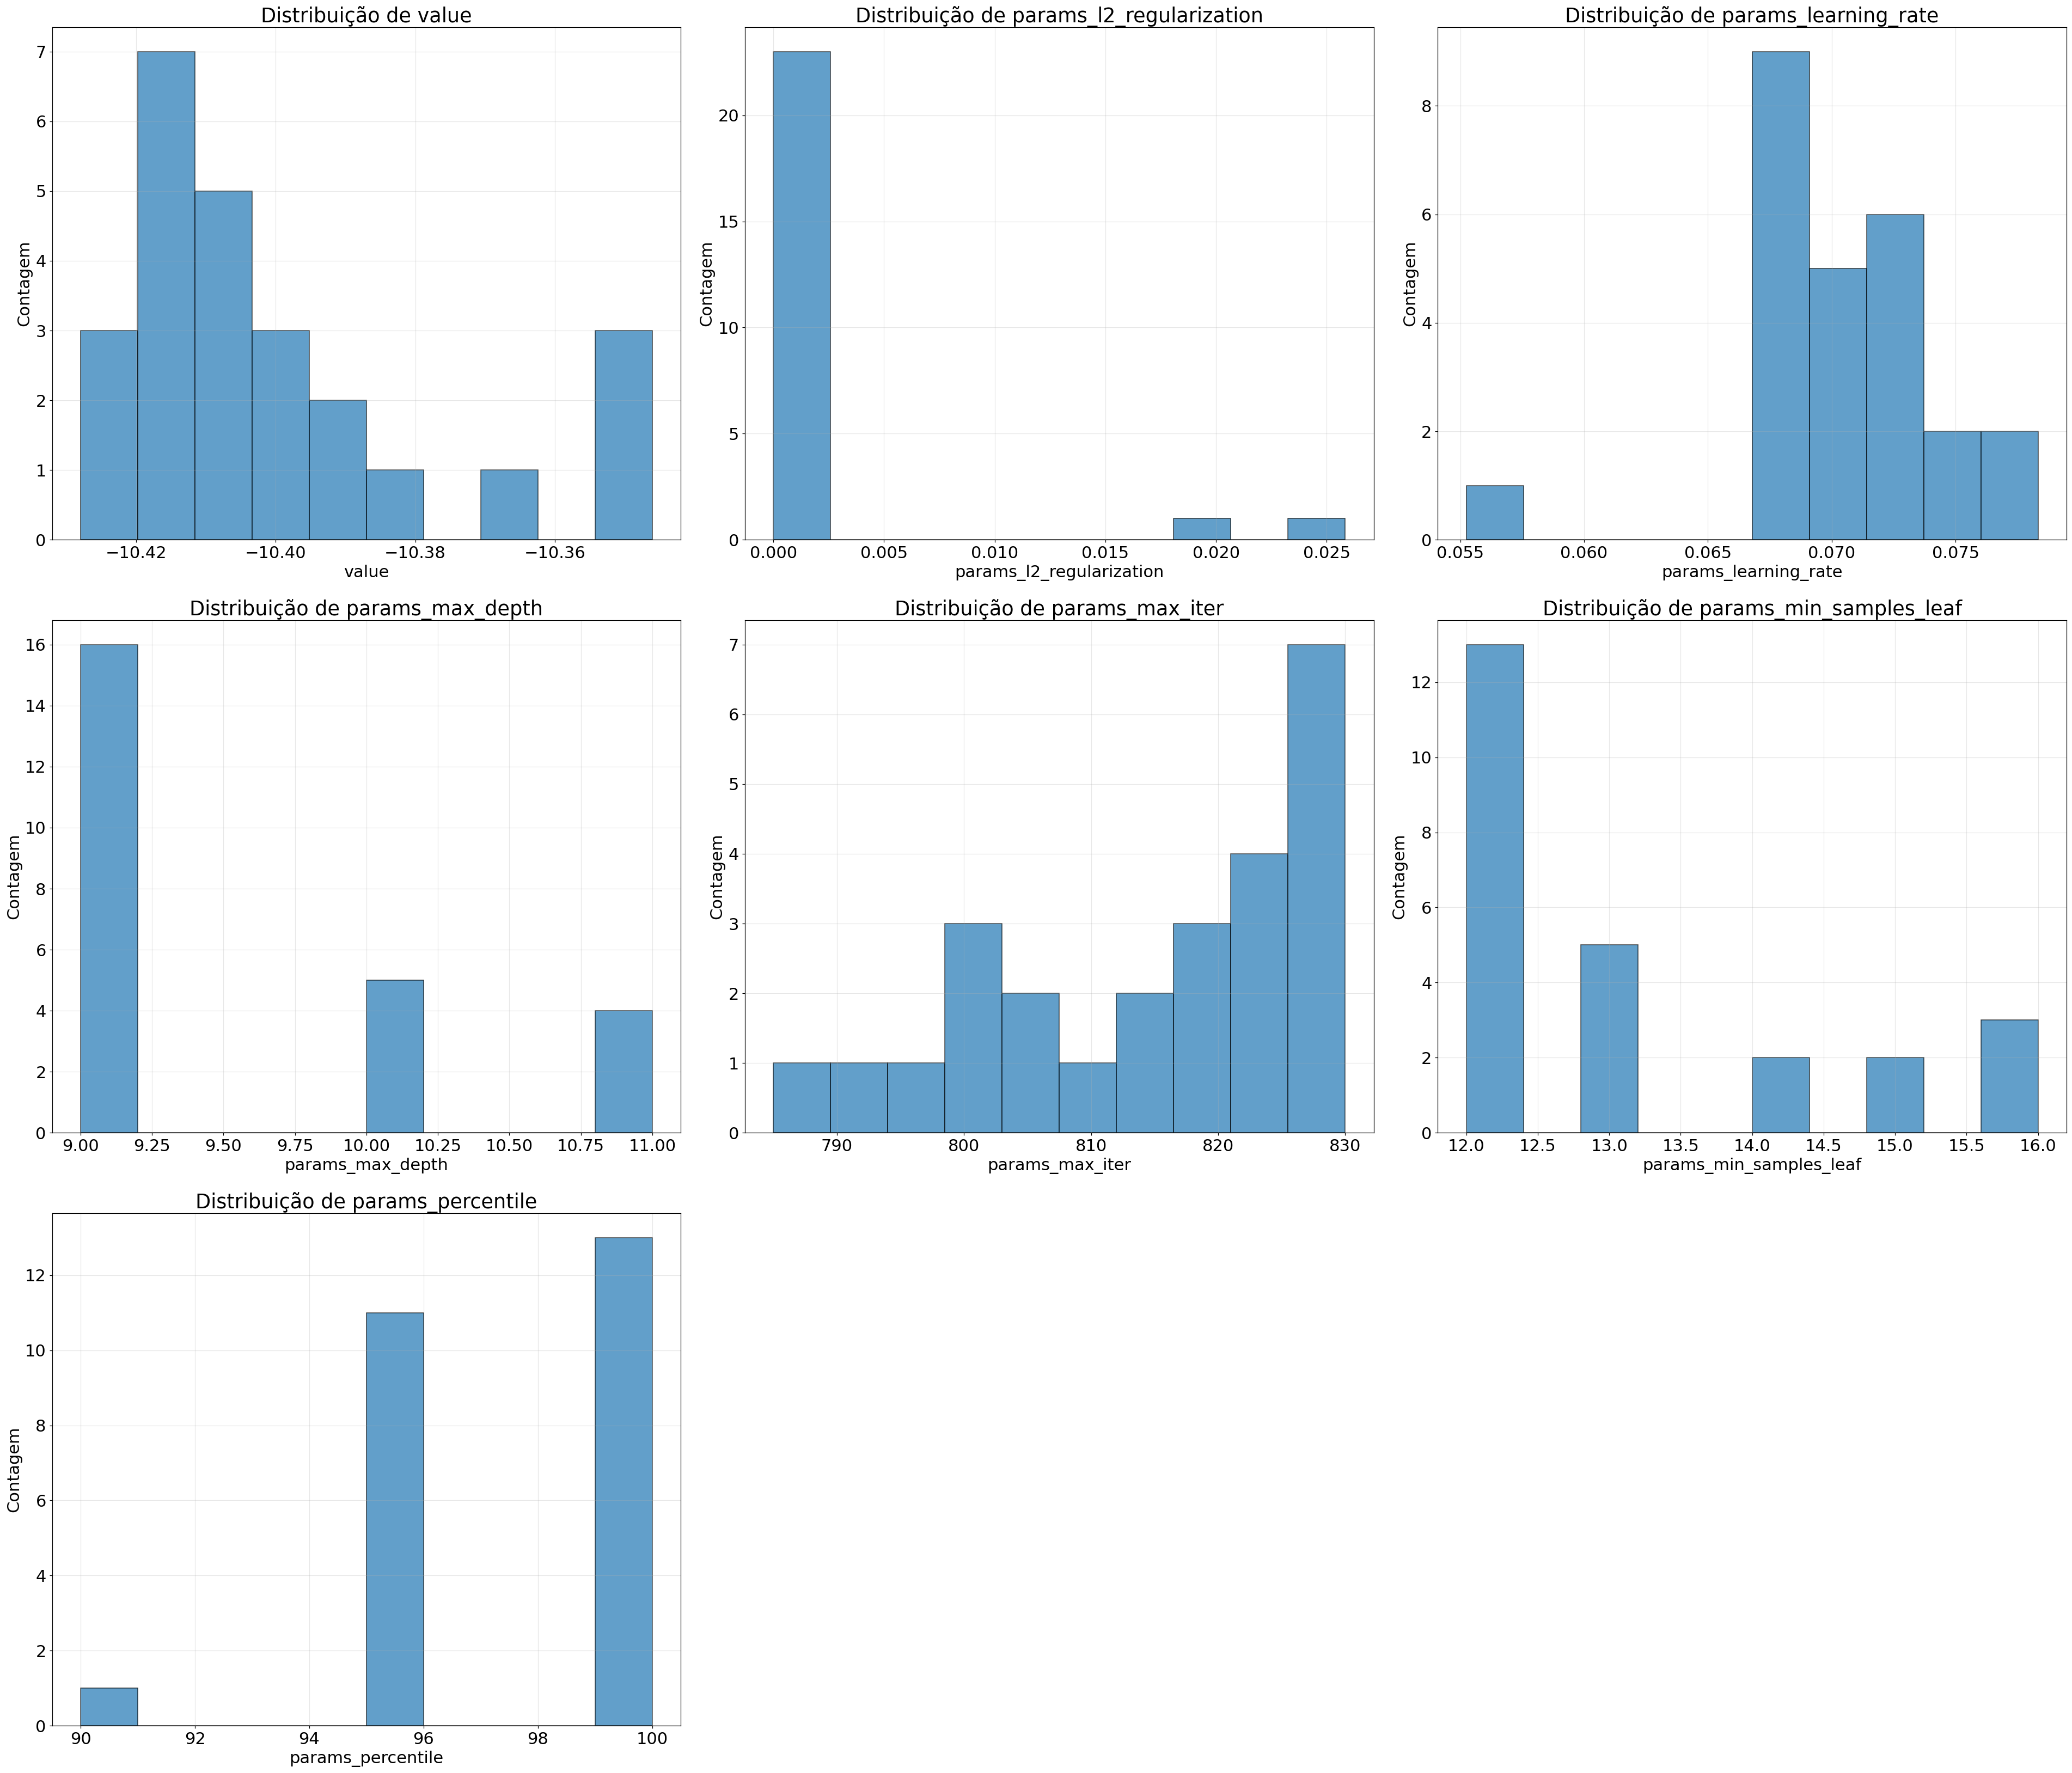

In [78]:
df_HGB = obter_df('HGB_ciclo3')
melhores_HGB = melhores_scores(df_HGB)
plotar(melhores_HGB)

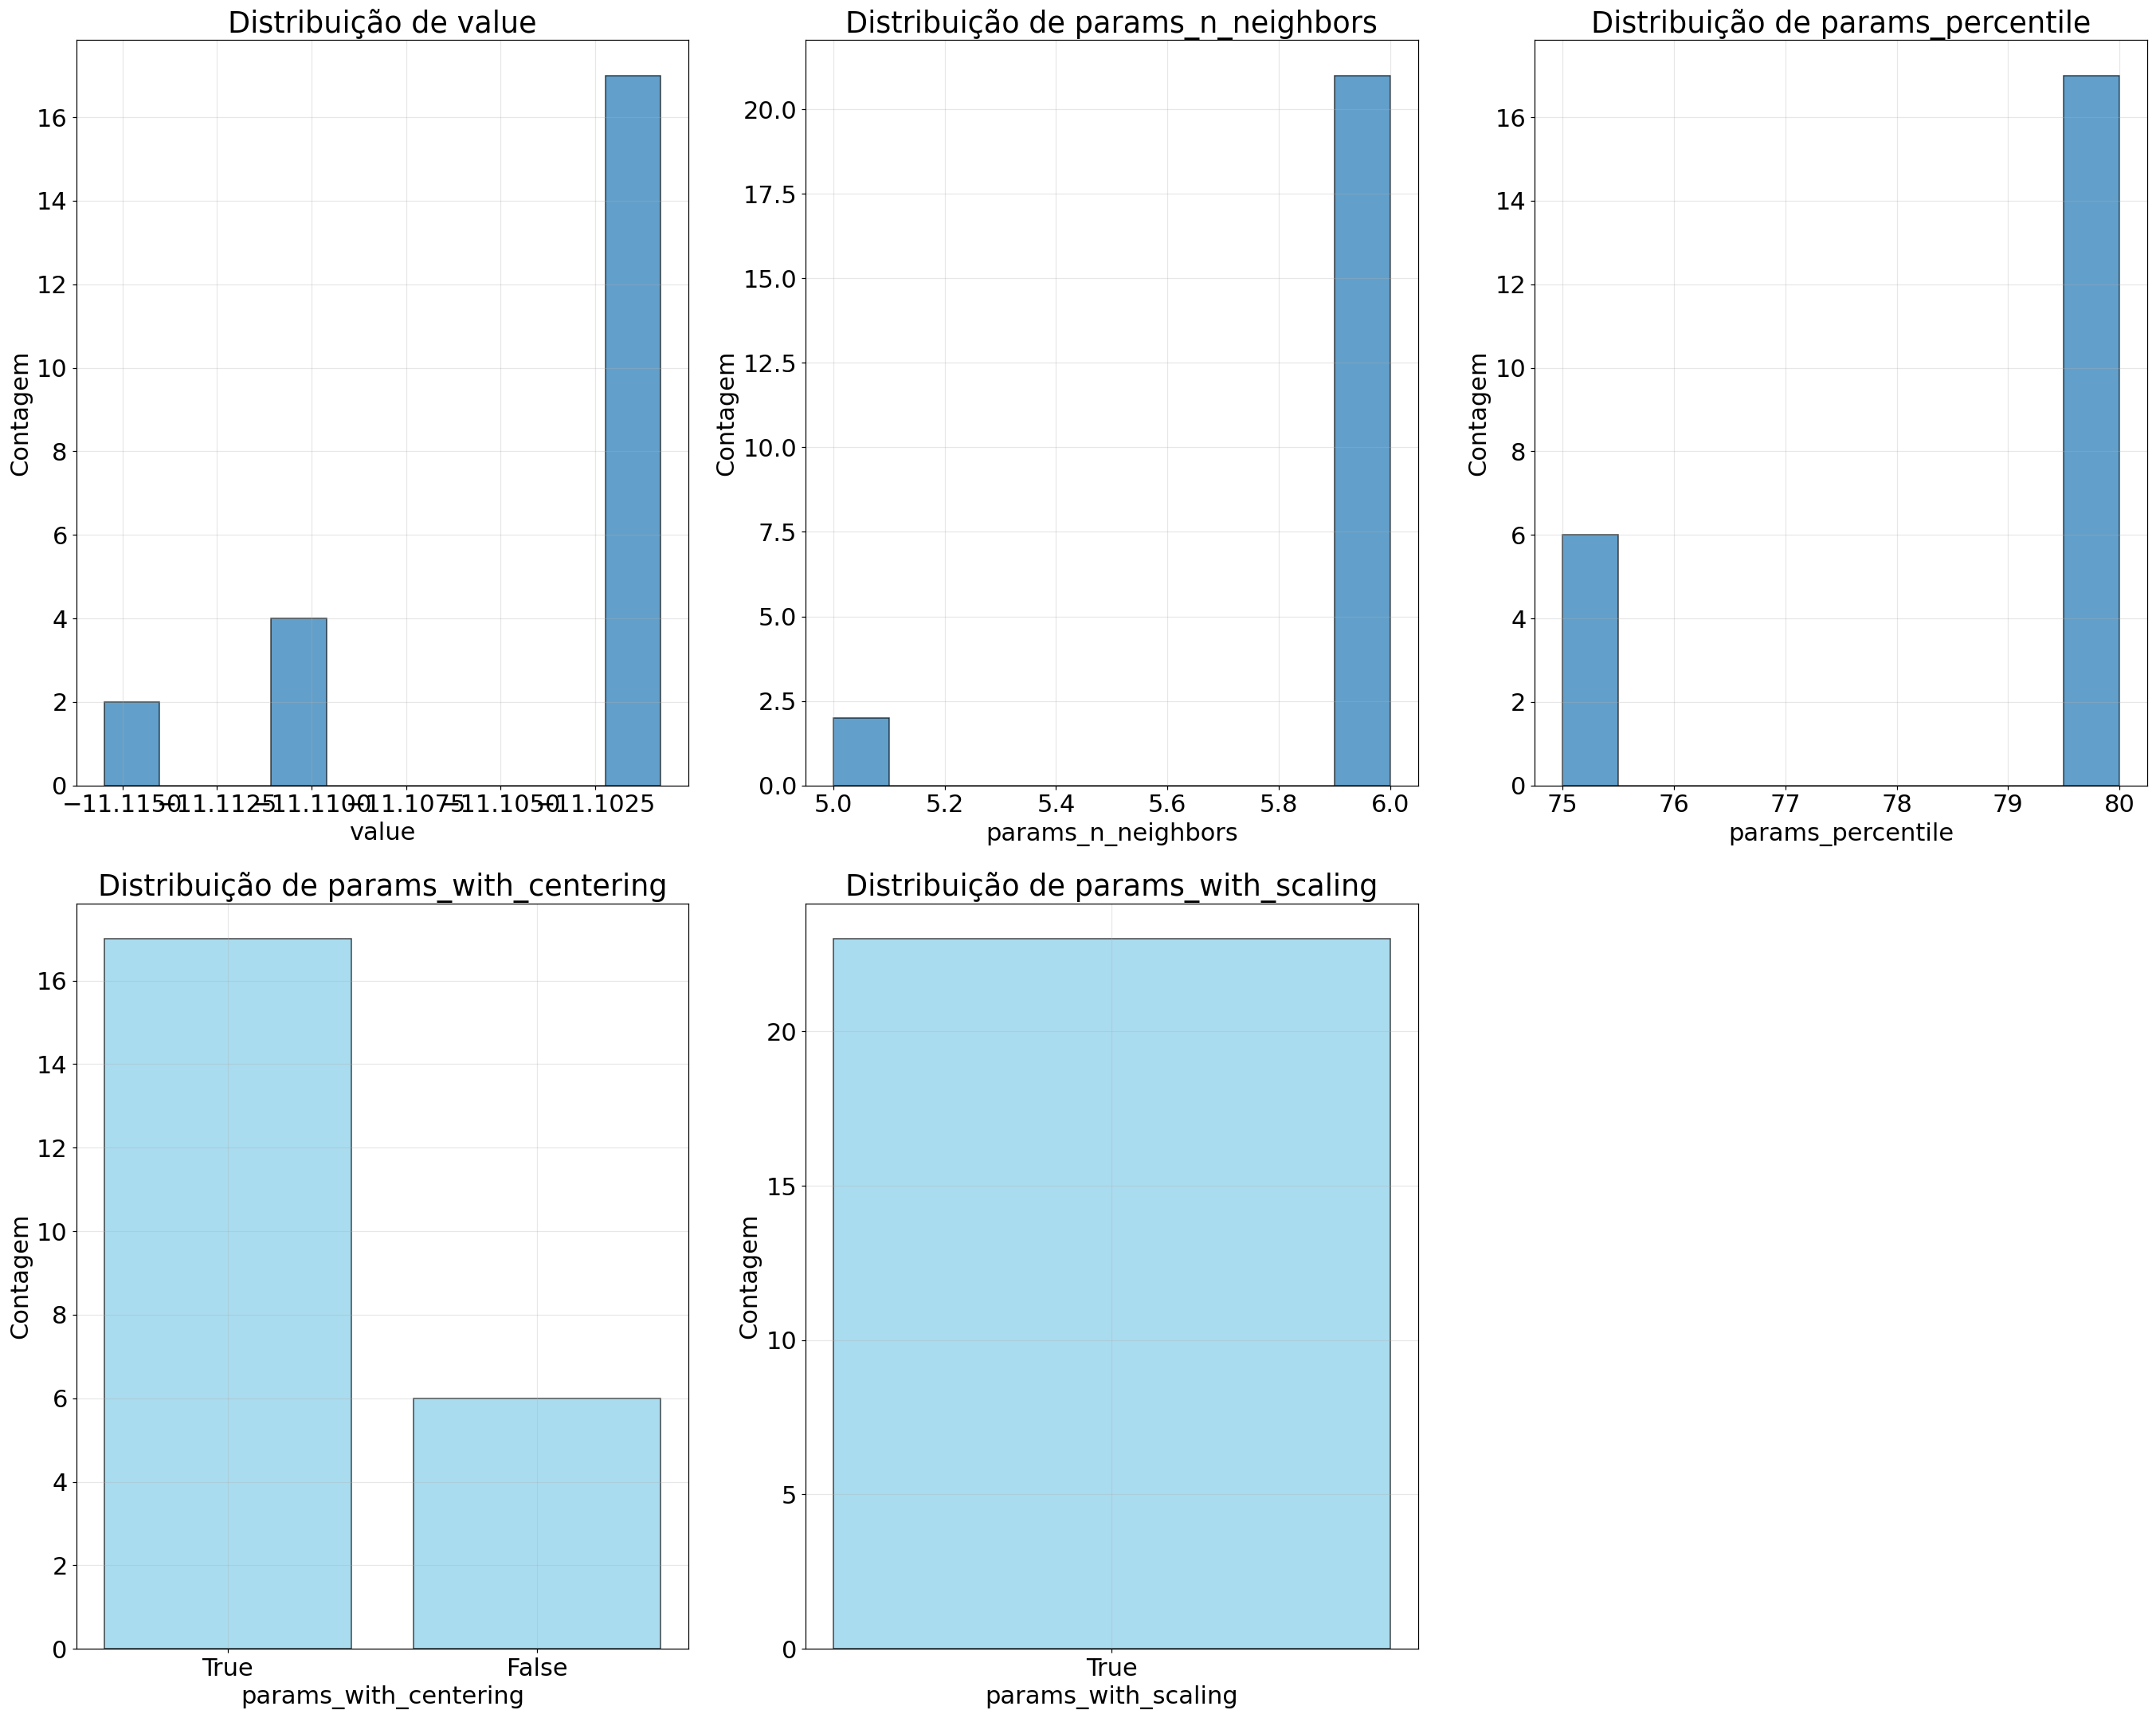

In [79]:
df_KNN = obter_df('KNN_ciclo3')
melhores_KNN = melhores_scores(df_KNN)
plotar(melhores_KNN)

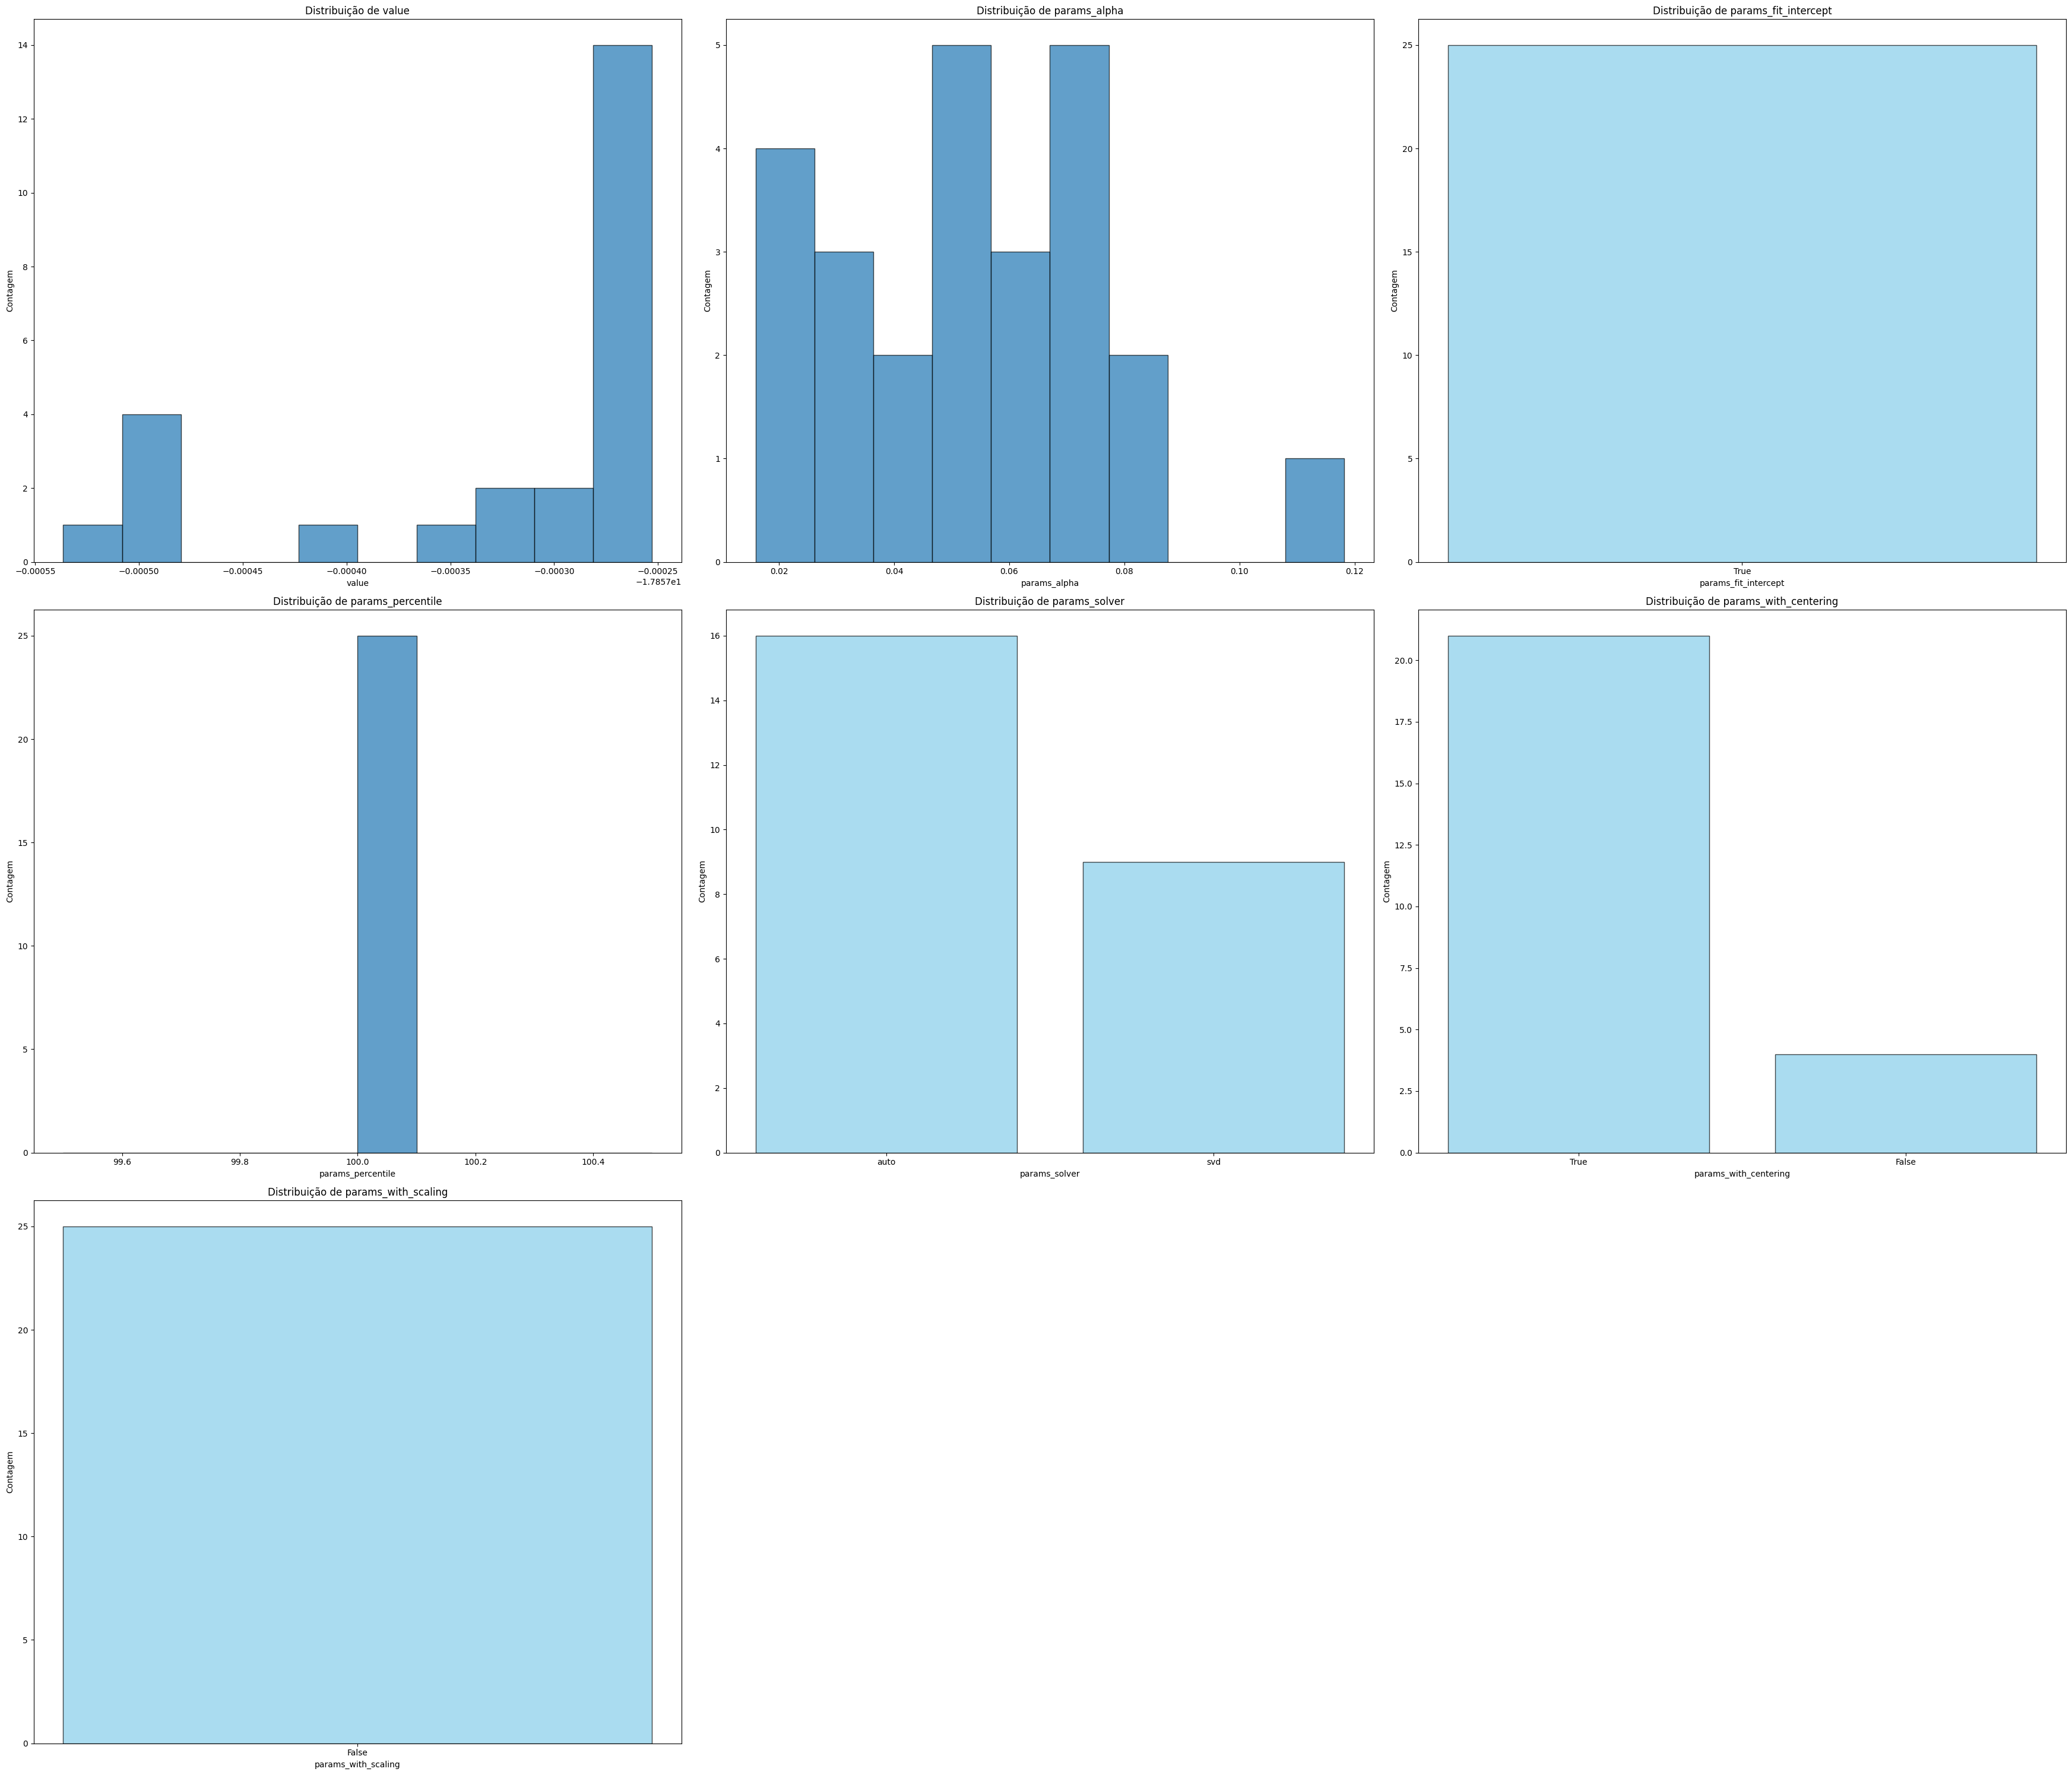

In [ ]:
df_RIDGE = obter_df('testando_RIDGE3')
melhores_RIDGE = melhores_scores(df_RIDGE)
plotar(melhores_RIDGE)

## Ciclo 4 (ciclo 3 para o RIDGE e o ETR)

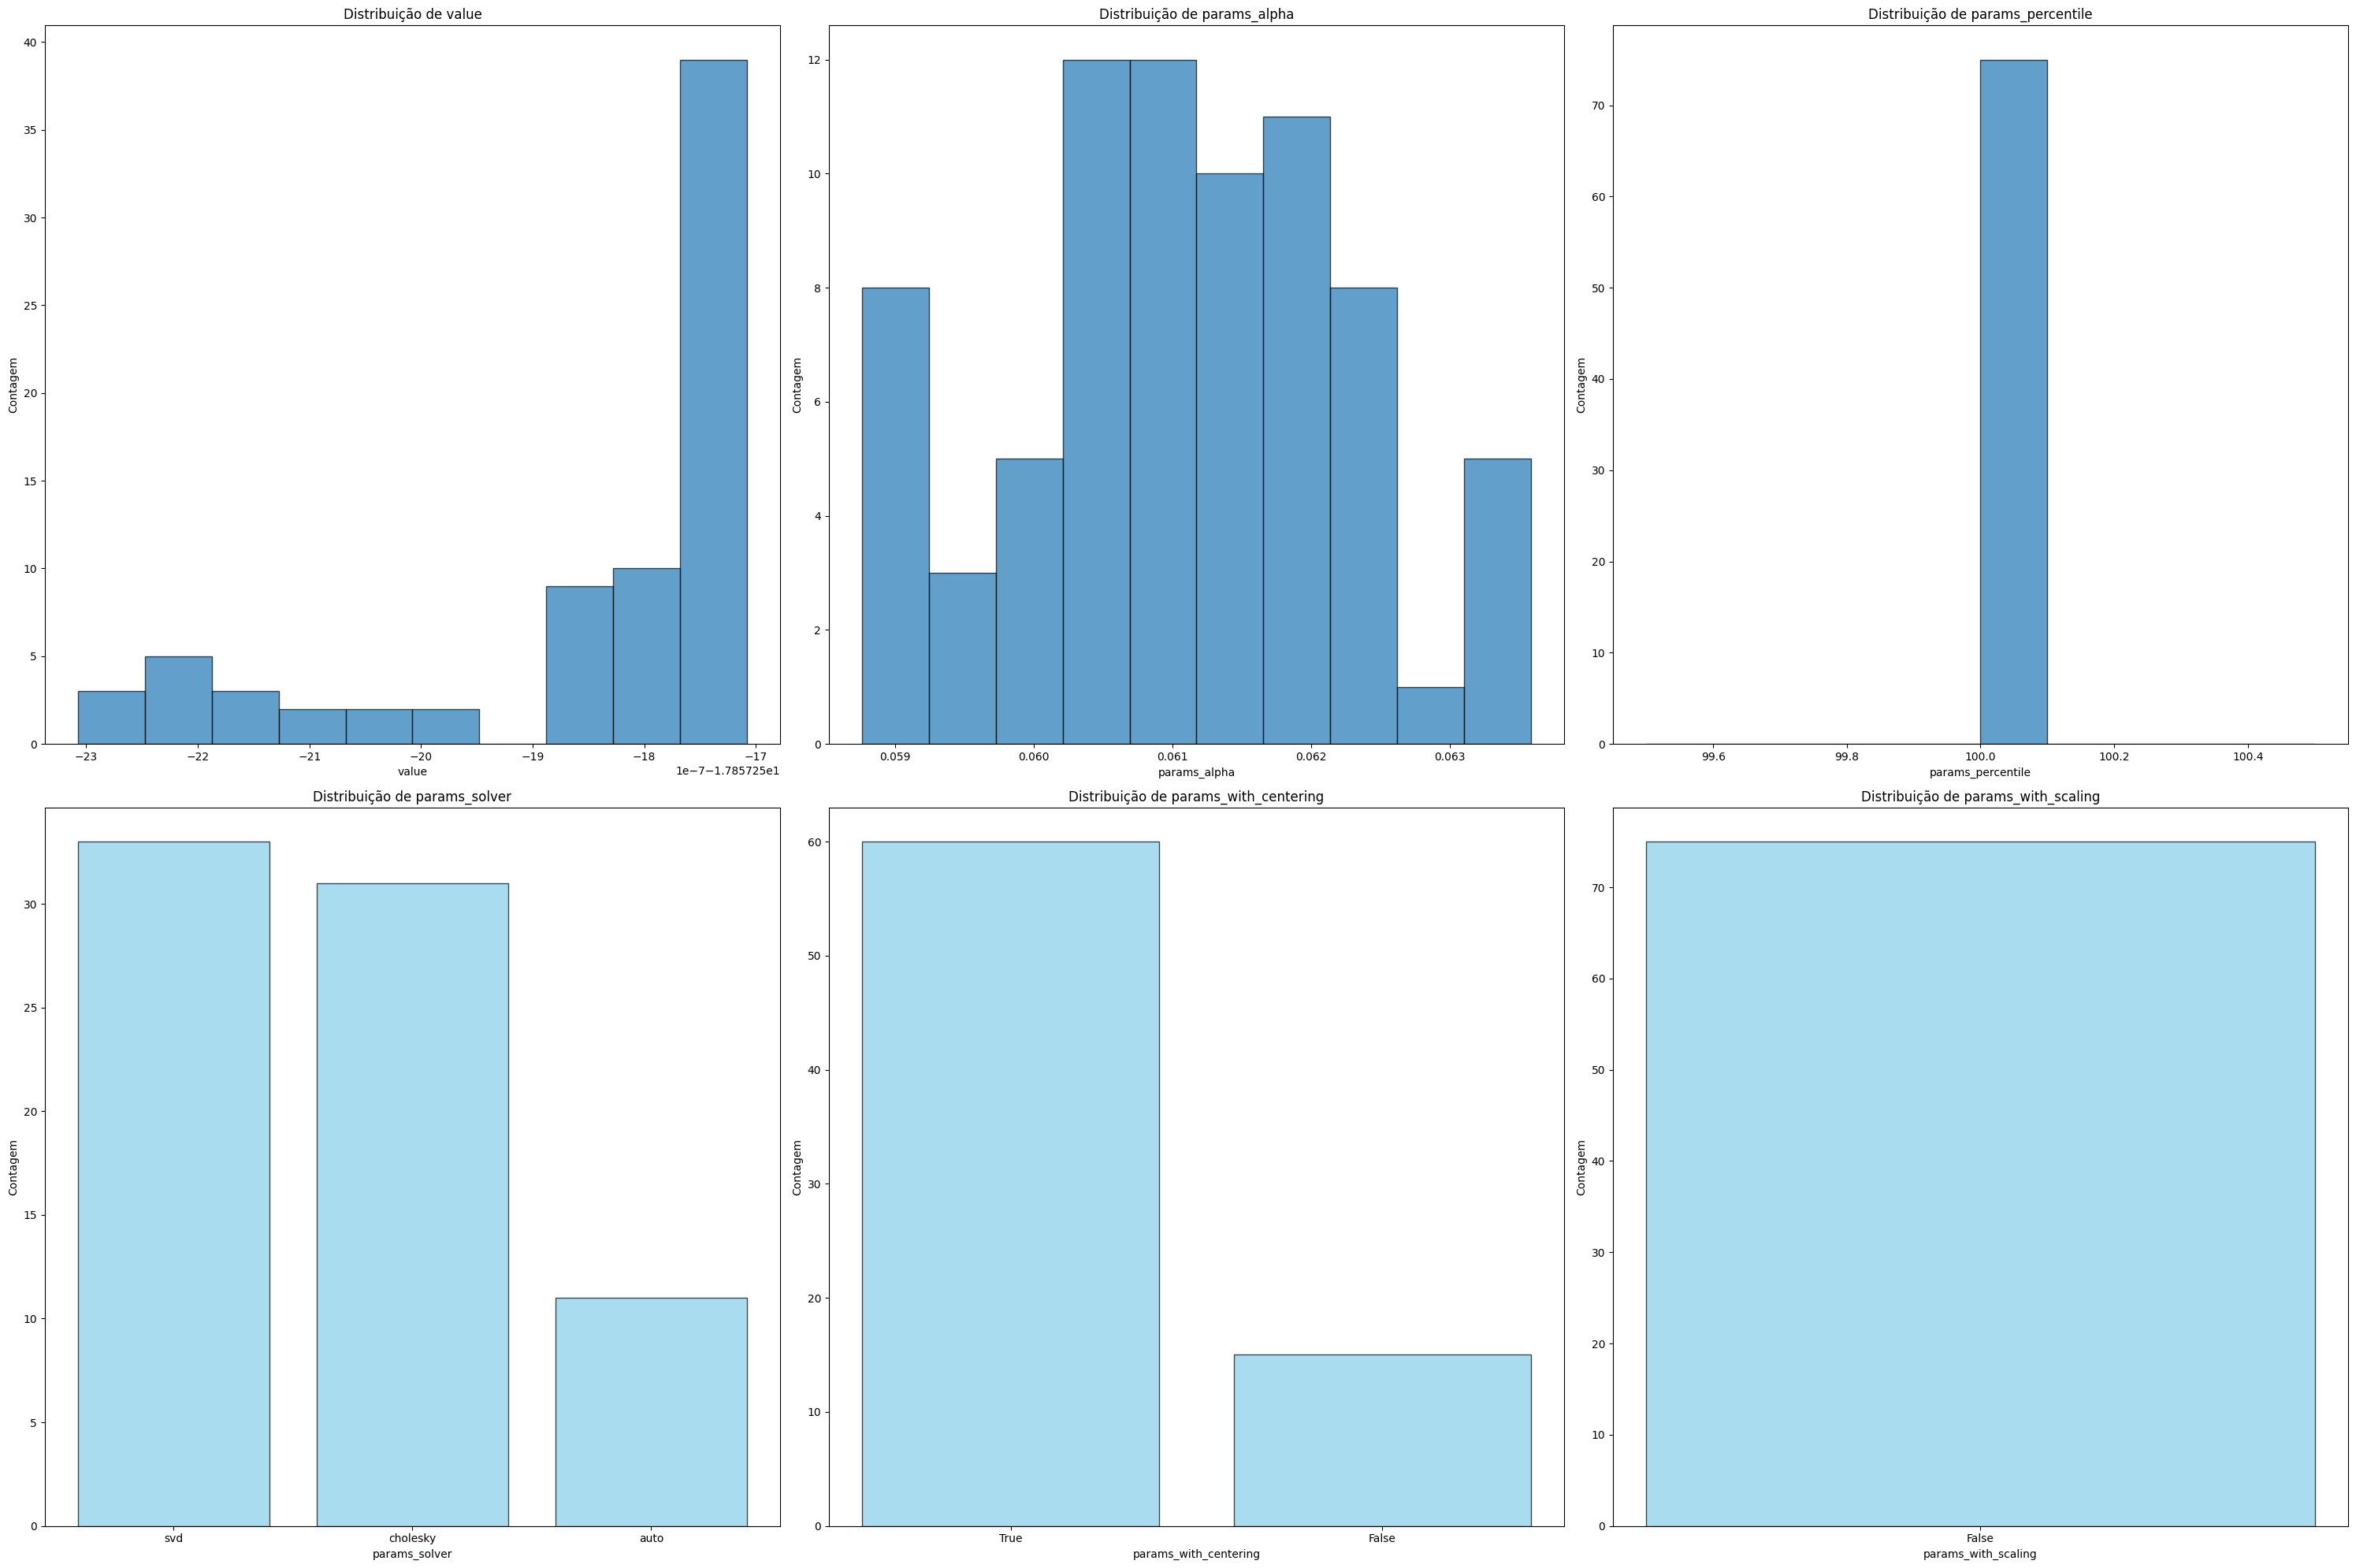

In [ ]:
ciclo('RIDGE_ciclo4')

In [49]:
estudo = optuna.load_study(study_name='Exodia_otm', storage=f"sqlite:///./otimizacao/E_EXODIA/studies/Exodia_otm.db")
df = estudo.trials_dataframe()
df = df.dropna(axis=1)
df = df.drop(['number', 'datetime_start', 'datetime_complete', 'duration', 'state'], axis=1)
df

,value,params_alpha_RD,params_l2_regularization_HGB,params_learning_rate_HGB,params_max_depth_ETR,params_max_depth_HGB,params_max_features_ETR,params_max_iter_HGB,params_min_samples_leaf_ETR,params_min_samples_leaf_HGB,params_min_samples_split_ETR,params_n_neighbors_KNN,params_p_KNN,params_passthrough_FINAL,params_positive_RD
0,-9.971094,0.052768,0.000181,0.088225,50,8,0.848250,645,1,18,9,8,1,True,False
1,-9.959272,0.079955,0.000112,0.051196,36,7,0.683672,626,1,9,4,7,1,True,False
2,-9.970929,0.020261,0.011126,0.083465,39,9,0.876165,671,2,15,9,7,2,False,False
3,-9.944004,0.002690,0.000044,0.063920,36,8,0.582136,827,1,17,5,9,1,False,False
4,-11.358465,0.010835,0.000013,0.056242,39,8,0.781337,853,1,20,7,5,2,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,-9.941619,0.002464,0.000046,0.066469,32,10,0.609778,888,1,19,7,11,1,False,False
96,-9.943741,0.009756,0.000100,0.068317,32,9,0.607524,820,1,20,7,10,1,False,False
97,-9.947848,0.006368,0.000039,0.063342,38,10,0.672721,883,1,19,7,10,1,False,False
98,-9.937884,0.007031,0.000086,0.066008,35,10,0.638338,882,1,19,7,9,1,False,False


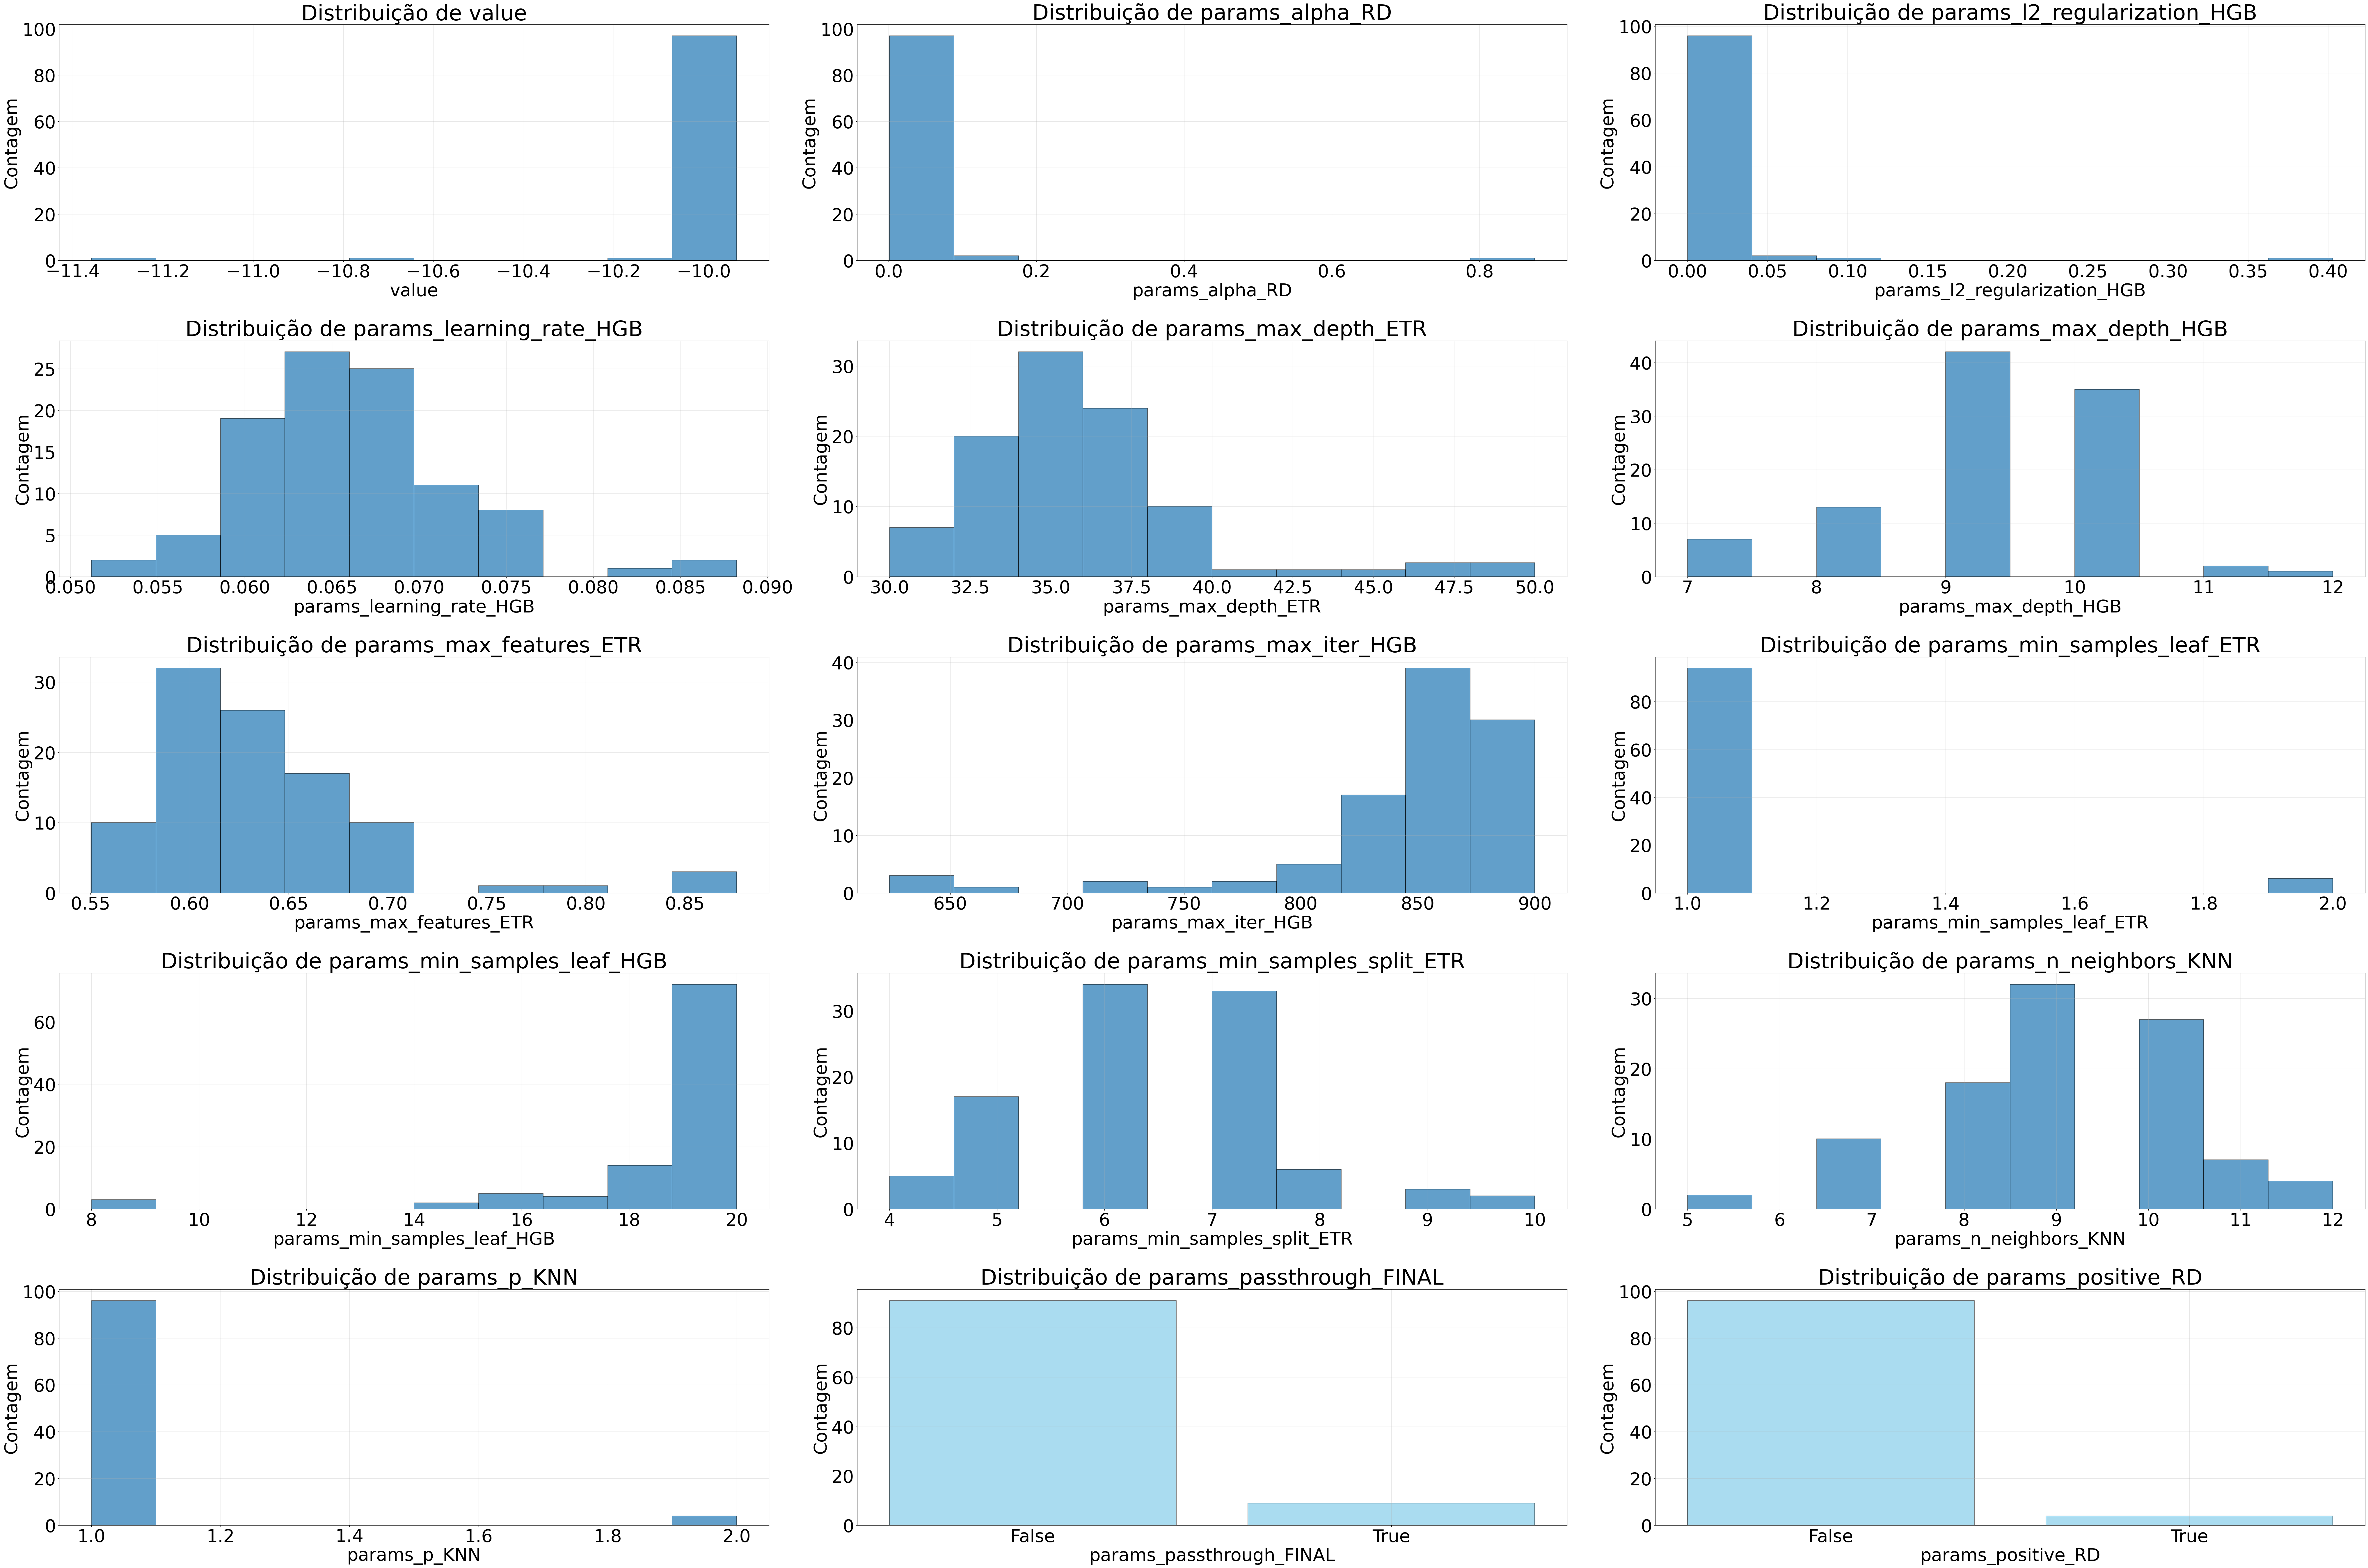

In [68]:
plotar(df)

## Pegando os melhores estimadores de cada ciclo e preparando o Exodia (estimador com stacking)


In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error as RMSE
import pandas as pd

df_treino = pd.read_csv('./otimizacao/data_TTV/df_treino.csv')
X_treino = df_treino.drop('critical_temp', axis=1)
y_treino = df_treino[['critical_temp']]

baseline = DummyRegressor()
baseline.fit(X_treino, y_treino)

df_val = pd.read_csv('./data_TTV/df_val.csv')
X_val = df_val.drop('critical_temp', axis=1)
y_val = df_val['critical_temp'].to_numpy()

y_prev = baseline.predict(X_val)
RMSE(y_true=y_val, y_pred=y_prev)


34.214162421488034

In [31]:
y_treino.describe()

,critical_temp
count,12757.000000
mean,34.334145
std,34.175378
min,0.000325
25%,5.400000
50%,20.000000
75%,63.000000
max,185.000000


In [17]:
estudo_knn = optuna.load_study(study_name='KNN_ciclo3', storage=f"sqlite:///./studies/KNN_ciclo3.db")
estudo_knn.best_params

{'percentile': 80,
 'n_neighbors': 6,
 'with_centering': True,
 'with_scaling': True}

In [18]:
estudo_HGB = optuna.load_study(study_name='HGB_ciclo3', storage=f"sqlite:///./studies/HGB_ciclo3.db")
estudo_HGB.best_params

{'percentile': 95,
 'learning_rate': 0.06922398679279254,
 'max_depth': 9,
 'min_samples_leaf': 12,
 'max_iter': 815,
 'l2_regularization': 0.0003949089535253511}

In [21]:
s = optuna.study.get_all_study_summaries(storage=f"sqlite:///./studies/RIDGE_ciclo4.db")
estudo_RIDGE = optuna.load_study(study_name=f'{s[0].study_name}', storage=f"sqlite:///./studies/RIDGE_ciclo4.db")
estudo_RIDGE.best_params

{'percentile': 100,
 'alpha': 0.0611963802960721,
 'solver': 'svd',
 'with_centering': True,
 'with_scaling': False}